In [1]:
from pathlib import Path
import pandas as pd
import numpy as np


PROJECT_DIR = Path.cwd().parent
OUTPUT_DIR = PROJECT_DIR / "ciktilar"
ANALIZ_DIR = OUTPUT_DIR / "analiz"
TEMIZ_VERI_DIR = OUTPUT_DIR / "temiz_veriler"

print("Proje dizini:", PROJECT_DIR)
print("Temiz veri dizini:", TEMIZ_VERI_DIR)
print("Analiz dizini:", ANALIZ_DIR)



Proje dizini: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study
Temiz veri dizini: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\temiz_veriler
Analiz dizini: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz


In [2]:
print("Temiz veri klasöründeki CSV dosyaları:\n")

for dosya in sorted(TEMIZ_VERI_DIR.glob("*.csv")):
    print(dosya.name)


aday_dosyalar = list(
    TEMIZ_VERI_DIR.glob("*geri*bildirim*.csv")
)

print("\nGeri bildirim dosyası adayları:")

for dosya in aday_dosyalar:
    print(dosya.name)

if len(aday_dosyalar) == 1:

    geri_bildirim_dosyasi = aday_dosyalar[0]

    geri_bildirim_df = pd.read_csv(
        geri_bildirim_dosyasi
    )

    print("\nDosya:", geri_bildirim_dosyasi.name)
    print("Veri boyutu:", geri_bildirim_df.shape)

    print("\nSütunlar:")
    print(geri_bildirim_df.columns.tolist())

    print("\nİlk 5 kayıt:")
    display(geri_bildirim_df.head())

    print("\nEksik değer sayıları:")
    display(geri_bildirim_df.isna().sum())

elif len(aday_dosyalar) == 0:
    print("\nGeri bildirim dosyası bulunamadı.")

else:
    print("\nBirden fazla aday dosya bulundu. Henüz seçim yapılmadı.")

Temiz veri klasöründeki CSV dosyaları:

araclar_temiz.csv
geri_bildirimler_temiz.csv
musteriler_temiz.csv
servis_kayitlari_temiz.csv

Geri bildirim dosyası adayları:
geri_bildirimler_temiz.csv

Dosya: geri_bildirimler_temiz.csv
Veri boyutu: (640, 5)

Sütunlar:
['geri_bildirim_id', 'arac_id', 'tarih', 'kanal', 'metin']

İlk 5 kayıt:


,geri_bildirim_id,arac_id,tarih,kanal,metin
0,9001,500339,2025-01-26,Çağrı Merkezi,Mükemmel değildi ama beklentimin altında da ka...
1,9002,500075,2023-11-22,Google Yorum,"Servis temizdi ve ekip güler yüzlüydü, yalnızc..."
2,9003,502791,2023-06-25,Anket,NaN
3,9004,500867,2023-07-05,Google Yorum,"Randevu saatinde gittim ama iki saat bekledim,..."
4,9005,500154,2023-11-02,Google Yorum,Yedek araç verilmesi büyük kolaylık oldu.



Eksik değer sayıları:


geri_bildirim_id     0
arac_id              0
tarih                0
kanal                0
metin               11
dtype: int64

In [3]:

geri_bildirim_df["tarih"] = pd.to_datetime(
    geri_bildirim_df["tarih"],
    errors="coerce"
)


kontroller = {
    "Toplam kayıt": len(geri_bildirim_df),
    "Benzersiz geri bildirim ID": geri_bildirim_df["geri_bildirim_id"].nunique(),
    "Tekrarlanan geri bildirim ID": geri_bildirim_df["geri_bildirim_id"].duplicated().sum(),
    "Geçersiz tarih": geri_bildirim_df["tarih"].isna().sum(),
    "Boş veya yalnızca boşluk içeren metin": (
        geri_bildirim_df["metin"].fillna("").str.strip().eq("").sum()
    ),
    "01.01.2022 öncesi kayıt": (
        geri_bildirim_df["tarih"] < "2022-01-01"
    ).sum(),
    "30.06.2025 sonrası kayıt": (
        geri_bildirim_df["tarih"] > "2025-06-30"
    ).sum()
}

for kontrol, sonuc in kontroller.items():
    print(f"{kontrol}: {sonuc}")

print("\nTarih aralığı:")
print("En eski:", geri_bildirim_df["tarih"].min())
print("En yeni:", geri_bildirim_df["tarih"].max())

print("\nKanal dağılımı:")
display(
    geri_bildirim_df["kanal"]
    .value_counts(dropna=False)
    .to_frame("kayit_sayisi")
)

Toplam kayıt: 640
Benzersiz geri bildirim ID: 640
Tekrarlanan geri bildirim ID: 0
Geçersiz tarih: 0
Boş veya yalnızca boşluk içeren metin: 11
01.01.2022 öncesi kayıt: 0
30.06.2025 sonrası kayıt: 0

Tarih aralığı:
En eski: 2023-01-13 00:00:00
En yeni: 2025-06-30 00:00:00

Kanal dağılımı:


,kayit_sayisi
kanal,
Anket,302
Google Yorum,125
Çağrı Merkezi,115
E-posta,98


**Analiz kararı:** 11 boş metinli kayıt korunacak ancak metin analizi örneklemine alınmayacak. Böylece LLM'e yalnızca gerçekten analiz edilebilir metinler gönderilecek.

In [4]:
# Boş metinleri örneklem dışında bırak
analiz_edilebilir = geri_bildirim_df[
    geri_bildirim_df["metin"].notna()
    & geri_bildirim_df["metin"].str.strip().ne("")
].copy()

# Sabit rastgele örneklem
llm_orneklem = analiz_edilebilir.sample(
    n=200,
    random_state=42
).copy()


llm_orneklem = llm_orneklem.sort_values(
    "geri_bildirim_id"
).reset_index(drop=True)


ANALIZ_DIR.mkdir(parents=True, exist_ok=True)

ORNEKLEM_DOSYASI = ANALIZ_DIR / "llm_orneklem_200.csv"

llm_orneklem.to_csv(
    ORNEKLEM_DOSYASI,
    index=False,
    encoding="utf-8-sig"
)

print("Analiz edilebilir metin sayısı:", len(analiz_edilebilir))
print("Örneklem kayıt sayısı:", len(llm_orneklem))
print("Benzersiz geri bildirim ID:", llm_orneklem["geri_bildirim_id"].nunique())
print("Boş metin sayısı:", llm_orneklem["metin"].isna().sum())
print("Kaydedilen dosya:", ORNEKLEM_DOSYASI)
print("Dosya mevcut mu:", ORNEKLEM_DOSYASI.exists())

print("\nÖrneklemden 10 kayıt:")
display(
    llm_orneklem[
        ["geri_bildirim_id", "tarih", "kanal", "metin"]
    ].head(10)
)

print("\nÖrneklem kanal dağılımı:")
display(
    llm_orneklem["kanal"]
    .value_counts()
    .to_frame("kayit_sayisi")
)

Analiz edilebilir metin sayısı: 629
Örneklem kayıt sayısı: 200
Benzersiz geri bildirim ID: 200
Boş metin sayısı: 0
Kaydedilen dosya: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\llm_orneklem_200.csv
Dosya mevcut mu: True

Örneklemden 10 kayıt:


,geri_bildirim_id,tarih,kanal,metin
0,9001,2025-01-26,Çağrı Merkezi,Mükemmel değildi ama beklentimin altında da ka...
1,9004,2023-07-05,Google Yorum,"Randevu saatinde gittim ama iki saat bekledim,..."
2,9008,2024-01-15,Anket,Fena değildi.
3,9011,2023-08-16,Çağrı Merkezi,İyi.
4,9012,2025-03-03,Anket,"Randevu almak kolaydı, işlem hızlı bitti. Memn..."
5,9013,2024-03-14,Çağrı Merkezi,"Aracımın içinde yağ lekesi bıraktılar, koltuk ..."
6,9017,2023-07-27,Anket,Teşekkürler
7,9025,2024-07-21,Anket,"Danışman bey her adımı tek tek anlattı, fiyat ..."
8,9026,2023-05-07,E-posta,"Danışman ilgisizdi, sorduğum soruya doğru düzg..."
9,9031,2023-02-01,Anket,?



Örneklem kanal dağılımı:


,kayit_sayisi
kanal,
Anket,104
Çağrı Merkezi,34
Google Yorum,33
E-posta,29


In [5]:
# 200 kayıtlık örneklemden 40 kayıtlık altın set seçimi
altin_set = llm_orneklem.sample(
    n=40,
    random_state=2026
).copy()

altin_set = altin_set.sort_values(
    "geri_bildirim_id"
).reset_index(drop=True)


altin_set["duygu"] = ""
altin_set["konular"] = ""


ALTIN_SET_DOSYASI = ANALIZ_DIR / "altin_set.csv"

altin_set.to_csv(
    ALTIN_SET_DOSYASI,
    index=False,
    encoding="utf-8-sig"
)

print("Altın set kayıt sayısı:", len(altin_set))
print("Benzersiz geri bildirim ID:", altin_set["geri_bildirim_id"].nunique())
print("Dosya mevcut mu:", ALTIN_SET_DOSYASI.exists())
print("\nElle etiketlenecek kayıtlar:")

display(
    altin_set[
        ["geri_bildirim_id", "kanal", "metin", "duygu", "konular"]
    ]
)

Altın set kayıt sayısı: 40
Benzersiz geri bildirim ID: 40
Dosya mevcut mu: True

Elle etiketlenecek kayıtlar:


,geri_bildirim_id,kanal,metin,duygu,konular
0,9013,Çağrı Merkezi,"Aracımın içinde yağ lekesi bıraktılar, koltuk ...",,
1,9017,Anket,Teşekkürler,,
2,9035,Anket,"İkinci kez geliyorum, yine sorunsuz. Ekibe teş...",,
3,9044,Anket,Sorun yok.,,
4,9075,Anket,Rakip markanın servisinde aynı işlem daha ucuz...,,
5,9082,Anket,"Danışman bey her adımı tek tek anlattı, fiyat ...",,
6,9084,E-posta,Yedek araç verilmesi büyük kolaylık oldu.,,
7,9114,Anket,"İkinci kez geliyorum, yine sorunsuz. Ekibe teş...",,
8,9121,Anket,Mükemmel değildi ama beklentimin altında da ka...,,
9,9135,Anket,"Randevu almak kolaydı, işlem hızlı bitti. Memn...",,


In [6]:
import pandas as pd

XLSX_DOSYASI = ANALIZ_DIR / "altin_set_etiketli.xlsx"
CSV_DOSYASI = ANALIZ_DIR / "altin_set_etiketli.csv"

# Excel dosyasını oku
altin_set = pd.read_excel(XLSX_DOSYASI)

# Tarihi standart YYYY-MM-DD formatına dönüştür
altin_set["tarih"] = pd.to_datetime(
    altin_set["tarih"],
    errors="raise"
).dt.strftime("%Y-%m-%d")

# UTF-8 BOM ile CSV kaydet
altin_set.to_csv(
    CSV_DOSYASI,
    index=False,
    encoding="utf-8-sig"
)

print("CSV kaydedildi:", CSV_DOSYASI)
print("\nİlk 5 tarih:")
print(altin_set["tarih"].head().to_list())

CSV kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\altin_set_etiketli.csv

İlk 5 tarih:
['1970-01-01', '1970-01-01', '1970-01-01', '1970-01-01', '1970-01-01']


In [7]:

XLSX_DOSYASI = ANALIZ_DIR / "altin_set_etiketli.xlsx"

altin_set = pd.read_excel(XLSX_DOSYASI)


orijinal_tarihler = llm_orneklem[
    ["geri_bildirim_id", "tarih"]
].copy()


altin_set = altin_set.drop(columns=["tarih"], errors="ignore")

altin_set = altin_set.merge(
    orijinal_tarihler,
    on="geri_bildirim_id",
    how="left",
    validate="one_to_one"
)


assert len(altin_set) == 40, "Kayıt sayısı 40 değil!"
assert altin_set["tarih"].notna().all(), "Eksik tarih var!"
assert altin_set["duygu"].notna().all(), "Eksik duygu etiketi var!"
assert altin_set["konular"].notna().all(), "Eksik konu etiketi var!"


altin_set["tarih"] = pd.to_datetime(
    altin_set["tarih"]
).dt.strftime("%Y-%m-%d")

# 6. CSV olarak kaydet
CSV_DOSYASI = ANALIZ_DIR / "altin_set_etiketli.csv"

altin_set.to_csv(
    CSV_DOSYASI,
    index=False,
    encoding="utf-8-sig"
)


kontrol = pd.read_csv(CSV_DOSYASI, encoding="utf-8-sig")

print("Kayıt sayısı:", len(kontrol))
print("Benzersiz ID:", kontrol["geri_bildirim_id"].nunique())
print("Eksik tarih:", kontrol["tarih"].isna().sum())
print("Eksik duygu:", kontrol["duygu"].isna().sum())
print("Eksik konu:", kontrol["konular"].isna().sum())

print("\nİlk 5 kayıt:")
display(kontrol.head(5))

Kayıt sayısı: 40
Benzersiz ID: 40
Eksik tarih: 0
Eksik duygu: 0
Eksik konu: 0

İlk 5 kayıt:


,geri_bildirim_id,arac_id,kanal,metin,duygu,konular,tarih
0,9013,501866,Çağrı Merkezi,"Aracımın içinde yağ lekesi bıraktılar, koltuk ...",Olumsuz,temizlik;iş_kalitesi,2024-03-14
1,9017,501428,Anket,Teşekkürler,Olumlu,diğer,2023-07-27
2,9035,504526,Anket,"İkinci kez geliyorum, yine sorunsuz. Ekibe teş...",Olumlu,iş_kalitesi;personel,2023-07-14
3,9044,500468,Anket,Sorun yok.,Olumlu,diğer,2023-02-17
4,9075,501189,Anket,Rakip markanın servisinde aynı işlem daha ucuz...,Olumsuz,fiyat,2025-03-29


In [8]:
%pip install -q -U google-genai python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import google.genai
import dotenv

import os
from dotenv import load_dotenv


ENV_DOSYASI = PROJECT_DIR / ".env"
load_dotenv(ENV_DOSYASI, override=True)


GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

if GEMINI_API_KEY:
    print("Gemini API anahtarı başarıyla yüklendi.")
else:
    print("API anahtarı bulunamadı. .env dosyasını kontrol et.")

Gemini API anahtarı başarıyla yüklendi.


In [10]:
from google import genai

client = genai.Client(api_key=GEMINI_API_KEY)

modeller = list(client.models.list())

flash_modelleri = [
    model.name
    for model in modeller
    if "flash" in model.name.lower()
]

print("Erişilebilen Flash modelleri:")
for model_adi in flash_modelleri:
    print("-", model_adi)

Erişilebilen Flash modelleri:
- models/gemini-2.5-flash
- models/gemini-2.5-flash-preview-tts
- models/gemini-flash-latest
- models/gemini-flash-lite-latest
- models/gemini-2.5-flash-lite
- models/gemini-2.5-flash-image
- models/gemini-3-flash-preview
- models/gemini-3.1-flash-lite-preview
- models/gemini-3.1-flash-lite
- models/gemini-3.1-flash-image-preview
- models/gemini-3.1-flash-image
- models/gemini-3.1-flash-lite-image
- models/gemini-3.5-flash
- models/gemini-3.5-flash-lite
- models/gemini-omni-flash-preview
- models/gemini-omni-1.1-flash
- models/gemini-3.6-flash
- models/gemini-3.7-flash
- models/gemini-3.8-flash
- models/gemini-3.1-flash-tts-preview
- models/gemini-3.8-flash-tts
- models/gemini-3.8-flash-lite-tts
- models/gemini-2.5-flash-native-audio-latest
- models/gemini-2.5-flash-native-audio-preview-09-2025
- models/gemini-2.5-flash-native-audio-preview-12-2025
- models/gemini-3.1-flash-live-preview


In [11]:
import json


GEMINI_MODEL = "gemini-3.5-flash-lite"


test_kaydi = llm_orneklem.iloc[0]
test_metin = str(test_kaydi["metin"])


prompt = f"""
Sen otomotiv yetkili servis müşteri geri bildirimlerini
sınıflandıran bir metin analiz asistanısın.

Aşağıdaki geri bildirimi sınıflandır.

DUYGU ETİKETLERİ:
- Olumlu: Memnuniyet, teşekkür veya olumlu deneyim.
- Olumsuz: Şikayet, memnuniyetsizlik veya sorun.
- Karışık: Hem olumlu hem olumsuz ifadeler.
- Alakasız: Servis deneyimi veya müşteri memnuniyetiyle ilgisiz içerik.

KONU ETİKETLERİ:
- randevu
- fiyat
- süre
- personel
- iş_kalitesi
- yedek_parça
- temizlik
- diğer

Birden fazla konu seçilebilir.
Listelenen konulardan hiçbiri uygun değilse yalnızca "diğer" seç.
Metinde açıkça belirtilmeyen bir konu veya duygu çıkarımı yapma.

GERİ BİLDİRİM:
{test_metin}
"""


response = client.models.generate_content(
    model=GEMINI_MODEL,
    contents=prompt,
    config={
        "response_mime_type": "application/json",
        "response_schema": {
            "type": "OBJECT",
            "properties": {
                "duygu": {
                    "type": "STRING",
                    "enum": ["Olumlu", "Olumsuz", "Karışık", "Alakasız"]
                },
                "konular": {
                    "type": "ARRAY",
                    "items": {
                        "type": "STRING",
                        "enum": [
                            "randevu", "fiyat", "süre", "personel",
                            "iş_kalitesi", "yedek_parça",
                            "temizlik", "diğer"
                        ]
                    }
                }
            },
            "required": ["duygu", "konular"]
        }
    }
)


sonuc = json.loads(response.text)

# Sonuçları göster
print("Kullanılan model:", GEMINI_MODEL)
print("Geri bildirim ID:", test_kaydi["geri_bildirim_id"])
print("Geri bildirim:", test_metin)

print("\nGemini yanıtı:")
print(json.dumps(sonuc, ensure_ascii=False, indent=2))

Kullanılan model: gemini-3.5-flash-lite
Geri bildirim ID: 9001
Geri bildirim: Mükemmel değildi ama beklentimin altında da kalmadı.

Gemini yanıtı:
{
  "duygu": "Karışık",
  "konular": [
    "diğer"
  ]
}


In [12]:
ALTIN_SET_DOSYASI = ANALIZ_DIR / "altin_set_etiketli.csv"

altin_set_kontrol = pd.read_csv(
    ALTIN_SET_DOSYASI,
    encoding="utf-8-sig"
)

altin_kayit = altin_set_kontrol[
    altin_set_kontrol["geri_bildirim_id"]
    == test_kaydi["geri_bildirim_id"]
]

if altin_kayit.empty:
    print("Bu kayıt altın sette bulunmuyor.")
else:
    manuel = altin_kayit.iloc[0]

    print("Geri bildirim ID:", manuel["geri_bildirim_id"])
    print("Manuel duygu:", manuel["duygu"])
    print("Gemini duygu:", sonuc["duygu"])

    print("\nManuel konular:", manuel["konular"])
    print("Gemini konular:", ";".join(sonuc["konular"]))

Bu kayıt altın sette bulunmuyor.


In [13]:
import json
import time
import pandas as pd
from pathlib import Path


GEMINI_MODEL = "gemini-3.5-flash-lite"

# İlk 5 kayıt
llm_ilk_grup = llm_orneklem.head(5).copy()

# Sonuç dosyası
LLM_SONUC_DOSYASI = ANALIZ_DIR / "llm_etiketleri.csv"

# Yapılandırılmış çıktı şeması
RESPONSE_SCHEMA = {
    "type": "OBJECT",
    "properties": {
        "duygu": {
            "type": "STRING",
            "enum": ["Olumlu", "Olumsuz", "Karışık", "Alakasız"]
        },
        "konular": {
            "type": "ARRAY",
            "items": {
                "type": "STRING",
                "enum": [
                    "randevu", "fiyat", "süre", "personel",
                    "iş_kalitesi", "yedek_parça",
                    "temizlik", "diğer"
                ]
            }
        }
    },
    "required": ["duygu", "konular"]
}


llm_sonuclari = []

for _, kayit in llm_ilk_grup.iterrows():

    geri_bildirim_id = kayit["geri_bildirim_id"]
    metin = str(kayit["metin"])

    prompt = f"""
Sen otomotiv yetkili servis müşteri geri bildirimlerini
sınıflandıran bir metin analiz asistanısın.

Aşağıdaki geri bildirimi sınıflandır.

DUYGU ETİKETLERİ:
- Olumlu: Memnuniyet, teşekkür veya olumlu deneyim.
- Olumsuz: Şikâyet, memnuniyetsizlik veya sorun.
- Karışık: Hem olumlu hem olumsuz ifadeler.
- Alakasız: Servis deneyimi veya müşteri memnuniyetiyle ilgisiz içerik.

KONU ETİKETLERİ:
- randevu
- fiyat
- süre
- personel
- iş_kalitesi
- yedek_parça
- temizlik
- diğer

Birden fazla konu seçilebilir.
Listelenen konulardan hiçbiri uygun değilse yalnızca "diğer" seç.
Metinde açıkça belirtilmeyen konu veya duygu çıkarımı yapma.
Yalnızca geri bildirimde açıkça ifade edilen konuları etiketle.

GERİ BİLDİRİM:
{metin}
"""

    try:
        response = client.models.generate_content(
            model=GEMINI_MODEL,
            contents=prompt,
            config={
                "response_mime_type": "application/json",
                "response_schema": RESPONSE_SCHEMA
            }
        )

        sonuc = json.loads(response.text)

        llm_sonuclari.append({
            "geri_bildirim_id": geri_bildirim_id,
            "duygu": sonuc["duygu"],
            "konular": ";".join(sonuc["konular"]),
            "model": GEMINI_MODEL,
            "hata": None
        })

        print(f"ID {geri_bildirim_id}: Başarılı")

    except Exception as e:
        llm_sonuclari.append({
            "geri_bildirim_id": geri_bildirim_id,
            "duygu": None,
            "konular": None,
            "model": GEMINI_MODEL,
            "hata": str(e)
        })

        print(f"ID {geri_bildirim_id}: Hata - {e}")

    time.sleep(2)


llm_sonuclari_df = pd.DataFrame(llm_sonuclari)


llm_sonuclari_df.to_csv(
    LLM_SONUC_DOSYASI,
    index=False,
    encoding="utf-8-sig"
)

print("\nİlk grup tamamlandı.")
print("Toplam kayıt:", len(llm_sonuclari_df))
print("Başarılı:", llm_sonuclari_df["hata"].isna().sum())
print("Hatalı:", llm_sonuclari_df["hata"].notna().sum())
print("Dosya:", LLM_SONUC_DOSYASI)

display(llm_sonuclari_df)

ID 9001: Başarılı
ID 9004: Başarılı
ID 9008: Başarılı
ID 9011: Hata - 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
ID 9012: Başarılı

İlk grup tamamlandı.
Toplam kayıt: 5
Başarılı: 4
Hatalı: 1
Dosya: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\llm_etiketleri.csv


,geri_bildirim_id,duygu,konular,model,hata
0,9001,Karışık,diğer,gemini-3.5-flash-lite,NaN
1,9004,Olumsuz,randevu;süre;personel,gemini-3.5-flash-lite,NaN
2,9008,Karışık,diğer,gemini-3.5-flash-lite,NaN
3,9011,NaN,NaN,gemini-3.5-flash-lite,"503 UNAVAILABLE. {'error': {'code': 503, 'mess..."
4,9012,Olumlu,randevu;süre,gemini-3.5-flash-lite,NaN


In [14]:
import json
import time
import pandas as pd


llm_sonuclari_df = pd.read_csv(
    LLM_SONUC_DOSYASI,
    encoding="utf-8-sig"
)


tamamlanan_idler = set(
    llm_sonuclari_df.loc[
        llm_sonuclari_df["hata"].isna(),
        "geri_bildirim_id"
    ]
)


bekleyen_kayitlar = llm_orneklem[
    ~llm_orneklem["geri_bildirim_id"].isin(tamamlanan_idler)
].copy()

print("Toplam örneklem:", len(llm_orneklem))
print("Başarıyla tamamlanan:", len(tamamlanan_idler))
print("Bekleyen kayıt:", len(bekleyen_kayitlar))


def geri_bildirim_siniflandir(metin):
    prompt = f"""
Sen otomotiv yetkili servis müşteri geri bildirimlerini
sınıflandıran bir metin analiz asistanısın.

DUYGU ETİKETLERİ:
- Olumlu: Memnuniyet, teşekkür veya olumlu deneyim.
- Olumsuz: Şikayet, memnuniyetsizlik veya sorun.
- Karışık: Hem olumlu hem olumsuz ifadeler.
- Alakasız: Servis deneyimi veya müşteri memnuniyetiyle ilgisiz içerik.

KONU ETİKETLERİ:
- randevu
- fiyat
- süre
- personel
- iş_kalitesi
- yedek_parça
- temizlik
- diğer

Birden fazla konu seçilebilir.
Listelenen konulardan hiçbiri uygun değilse yalnızca "diğer" seç.
Metinde açıkça belirtilmeyen konu veya duygu çıkarımı yapma.

GERİ BİLDİRİM:
{metin}
"""

    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=prompt,
        config={
            "response_mime_type": "application/json",
            "response_schema": RESPONSE_SCHEMA
        }
    )

    return json.loads(response.text)



for sira, (_, kayit) in enumerate(
    bekleyen_kayitlar.iterrows(), start=1
):

    geri_bildirim_id = kayit["geri_bildirim_id"]
    metin = str(kayit["metin"])

    try:
        sonuc = geri_bildirim_siniflandir(metin)

        yeni_kayit = {
            "geri_bildirim_id": geri_bildirim_id,
            "duygu": sonuc["duygu"],
            "konular": ";".join(sonuc["konular"]),
            "model": GEMINI_MODEL,
            "hata": None
        }

        print(f"{sira}/{len(bekleyen_kayitlar)} - ID {geri_bildirim_id}: Başarılı")

    except Exception as e:

        yeni_kayit = {
            "geri_bildirim_id": geri_bildirim_id,
            "duygu": None,
            "konular": None,
            "model": GEMINI_MODEL,
            "hata": str(e)
        }

        print(f"{sira}/{len(bekleyen_kayitlar)} - ID {geri_bildirim_id}: Hata")

    
    llm_sonuclari_df = pd.concat(
        [llm_sonuclari_df, pd.DataFrame([yeni_kayit])],
        ignore_index=True
    )

    
    if sira % 5 == 0:
        llm_sonuclari_df.to_csv(
            LLM_SONUC_DOSYASI,
            index=False,
            encoding="utf-8-sig"
        )

    time.sleep(2)


llm_sonuclari_df.to_csv(
    LLM_SONUC_DOSYASI,
    index=False,
    encoding="utf-8-sig"
)

print("\nİşlem tamamlandı.")
print("Toplam sonuç:", len(llm_sonuclari_df))
print("Başarılı:", llm_sonuclari_df["hata"].isna().sum())
print("Hatalı:", llm_sonuclari_df["hata"].notna().sum())

Toplam örneklem: 200
Başarıyla tamamlanan: 4
Bekleyen kayıt: 196
1/196 - ID 9011: Başarılı
2/196 - ID 9013: Başarılı
3/196 - ID 9017: Başarılı
4/196 - ID 9025: Başarılı
5/196 - ID 9026: Başarılı
6/196 - ID 9031: Başarılı
7/196 - ID 9032: Başarılı
8/196 - ID 9033: Başarılı
9/196 - ID 9035: Başarılı
10/196 - ID 9041: Başarılı
11/196 - ID 9043: Başarılı
12/196 - ID 9044: Başarılı
13/196 - ID 9051: Hata
14/196 - ID 9057: Hata
15/196 - ID 9058: Başarılı
16/196 - ID 9062: Başarılı
17/196 - ID 9066: Hata
18/196 - ID 9069: Başarılı
19/196 - ID 9071: Başarılı
20/196 - ID 9073: Başarılı
21/196 - ID 9075: Hata
22/196 - ID 9076: Hata
23/196 - ID 9078: Başarılı
24/196 - ID 9079: Hata
25/196 - ID 9080: Başarılı
26/196 - ID 9081: Başarılı
27/196 - ID 9082: Başarılı
28/196 - ID 9084: Başarılı
29/196 - ID 9085: Başarılı
30/196 - ID 9086: Başarılı
31/196 - ID 9087: Başarılı
32/196 - ID 9089: Hata
33/196 - ID 9091: Başarılı
34/196 - ID 9093: Başarılı
35/196 - ID 9096: Başarılı
36/196 - ID 9105: Hata
37/1

In [15]:

hata_kayitlari = llm_sonuclari_df[
    llm_sonuclari_df["hata"].notna()
].copy()

print("Toplam hatalı kayıt:", len(hata_kayitlari))

# Hata mesajlarının dağılımı
print("\nHata mesajlarının dağılımı:")

display(
    hata_kayitlari["hata"]
    .value_counts()
    .reset_index()
    .rename(columns={
        "index": "hata_mesaji",
        "count": "kayit_sayisi"
    })
)


print("\nİlk 5 hatalı kayıt:")

display(
    hata_kayitlari[
        ["geri_bildirim_id", "hata"]
    ].head(5)
)

Toplam hatalı kayıt: 53

Hata mesajlarının dağılımı:


,hata,kayit_sayisi
0,"503 UNAVAILABLE. {'error': {'code': 503, 'mess...",30
1,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...,1
2,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...,1
3,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...,1
4,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...,1
5,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...,1
6,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...,1
7,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...,1
8,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...,1
9,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...,1



İlk 5 hatalı kayıt:


,geri_bildirim_id,hata
3,9011,"503 UNAVAILABLE. {'error': {'code': 503, 'mess..."
17,9051,"503 UNAVAILABLE. {'error': {'code': 503, 'mess..."
18,9057,"503 UNAVAILABLE. {'error': {'code': 503, 'mess..."
21,9066,"503 UNAVAILABLE. {'error': {'code': 503, 'mess..."
25,9075,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...


In [16]:
ilk_hata = hata_kayitlari.iloc[0]["hata"]

print(ilk_hata)

503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}


In [ ]:

import time
import json
import pandas as pd

llm_sonuclari_df = pd.read_csv(
    LLM_SONUC_DOSYASI,
    encoding="utf-8-sig"
)

hata_kayitlari = llm_sonuclari_df[
    llm_sonuclari_df["hata"].notna()
].copy()

yeniden_isleme = hata_kayitlari.merge(
    llm_orneklem[["geri_bildirim_id", "metin"]],
    on="geri_bildirim_id",
    how="left",
    validate="one_to_one"
)

print("Yeniden işlenecek kayıt:", len(yeniden_isleme))

for sira, (_, kayit) in enumerate(
    yeniden_isleme.iterrows(), start=1
):
    geri_bildirim_id = kayit["geri_bildirim_id"]
    indeks = llm_sonuclari_df.index[
        llm_sonuclari_df["geri_bildirim_id"]
        == geri_bildirim_id
    ][0]

    basarili = False

    for deneme in range(1, 5):
        try:
            sonuc = geri_bildirim_siniflandir(
                str(kayit["metin"])
            )

            llm_sonuclari_df.loc[indeks, "duygu"] = sonuc["duygu"]
            llm_sonuclari_df.loc[indeks, "konular"] = ";".join(
                sonuc["konular"]
            )
            llm_sonuclari_df.loc[indeks, "hata"] = None

            basarili = True
            break

        except Exception as e:
            hata_mesaji = str(e)
            llm_sonuclari_df.loc[indeks, "hata"] = hata_mesaji

            print(
                f"ID {geri_bildirim_id} | "
                f"Deneme {deneme}/4 | Hata: {hata_mesaji[:150]}"
            )

            if deneme < 4:
                bekleme = 5 * (2 ** (deneme - 1))
                time.sleep(bekleme)

    durum = "Başarılı" if basarili else "Başarısız"

    print(
        f"{sira}/{len(yeniden_isleme)} "
        f"- ID {geri_bildirim_id}: {durum}"
    )

    llm_sonuclari_df.to_csv(
        LLM_SONUC_DOSYASI,
        index=False,
        encoding="utf-8-sig"
    )

    time.sleep(5)

print("\nYeniden deneme tamamlandı.")
print("Toplam kayıt:", len(llm_sonuclari_df))
print("Başarılı:", llm_sonuclari_df["hata"].isna().sum())
print("Hatalı:", llm_sonuclari_df["hata"].notna().sum())


Yeniden işlenecek kayıt: 53
1/53 - ID 9011: Başarılı
2/53 - ID 9051: Başarılı
ID 9057 | Deneme 1/4 | Hata: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please 
3/53 - ID 9057: Başarılı
4/53 - ID 9066: Başarılı
5/53 - ID 9075: Başarılı
6/53 - ID 9076: Başarılı
7/53 - ID 9079: Başarılı
8/53 - ID 9089: Başarılı
9/53 - ID 9105: Başarılı
10/53 - ID 9118: Başarılı
11/53 - ID 9121: Başarılı
12/53 - ID 9122: Başarılı
ID 9135 | Deneme 1/4 | Hata: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please 
13/53 - ID 9135: Başarılı
14/53 - ID 9194: Başarılı
ID 9198 | Deneme 1/4 | Hata: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please 
15/53 - ID 9198: Başarılı
16/53 - ID 9202: Başarılı
17/53 - ID 9205: Başarılı

In [19]:
print("Toplam satır:", len(llm_sonuclari_df))
print("Benzersiz geri bildirim:", llm_sonuclari_df["geri_bildirim_id"].nunique())

tekrar_edenler = llm_sonuclari_df[
    llm_sonuclari_df["geri_bildirim_id"].duplicated(keep=False)
].sort_values("geri_bildirim_id")

print("\nTekrarlanan kayıtlar:")
display(tekrar_edenler)

Toplam satır: 201
Benzersiz geri bildirim: 200

Tekrarlanan kayıtlar:


,geri_bildirim_id,duygu,konular,model,hata
3,9011,Olumlu,diğer,gemini-3.5-flash-lite,NaN
5,9011,Olumlu,diğer,gemini-3.5-flash-lite,NaN


In [20]:
# V1 sonuçlarını tekilleştirme
llm_sonuclari_df = llm_sonuclari_df.drop_duplicates(
    subset="geri_bildirim_id",
    keep="last"
).copy()


print("Toplam kayıt:", len(llm_sonuclari_df))
print("Benzersiz ID:", llm_sonuclari_df["geri_bildirim_id"].nunique())
print("Başarılı:", llm_sonuclari_df["hata"].isna().sum())
print("Hatalı:", llm_sonuclari_df["hata"].notna().sum())

# Mevcut sonuç dosyasının üzerine kaydet
llm_sonuclari_df.to_csv(
    LLM_SONUC_DOSYASI,
    index=False,
    encoding="utf-8-sig"
)

print("\nTemizlenmiş V1 sonuçları kaydedildi:", LLM_SONUC_DOSYASI)

Toplam kayıt: 200
Benzersiz ID: 200
Başarılı: 200
Hatalı: 0

Temizlenmiş V1 sonuçları kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\llm_etiketleri.csv


In [21]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

# 1. Altın set ve LLM sonuçları
altin_set = pd.read_csv(
    ANALIZ_DIR / "altin_set_etiketli.csv",
    encoding="utf-8-sig"
)

llm_sonuclari_df = pd.read_csv(
    LLM_SONUC_DOSYASI,
    encoding="utf-8-sig"
)

# 2. Veri kontrolleri
print("Altın set kayıt sayısı:", len(altin_set))
print("Altın set benzersiz ID:", altin_set["geri_bildirim_id"].nunique())

print("LLM sonuç kayıt sayısı:", len(llm_sonuclari_df))
print("LLM benzersiz ID:", llm_sonuclari_df["geri_bildirim_id"].nunique())
print("LLM hatalı kayıt:", llm_sonuclari_df["hata"].notna().sum())

# 3. Altın set ile LLM sonuçlarını eşleştirme
karsilastirma = altin_set.merge(
    llm_sonuclari_df[
        ["geri_bildirim_id", "duygu", "konular"]
    ],
    on="geri_bildirim_id",
    how="left",
    validate="one_to_one",
    suffixes=("_manuel", "_llm")
)

assert len(karsilastirma) == 40
assert karsilastirma["duygu_llm"].notna().all()
assert karsilastirma["konular_llm"].notna().all()

# 4. Duygu sınıflandırma performansı
y_true_duygu = karsilastirma["duygu_manuel"].str.strip()
y_pred_duygu = karsilastirma["duygu_llm"].str.strip()

print("\n--- DUYGU SINIFLANDIRMA ---")

print("Accuracy:", round(
    accuracy_score(y_true_duygu, y_pred_duygu), 4
))

print("\nSınıf bazında performans:")
print(classification_report(
    y_true_duygu,
    y_pred_duygu,
    labels=["Olumlu", "Olumsuz", "Karışık", "Alakasız"],
    zero_division=0
))

print("Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(
        y_true_duygu,
        y_pred_duygu,
        labels=["Olumlu", "Olumsuz", "Karışık", "Alakasız"]
    ),
    index=["Gerçek Olumlu", "Gerçek Olumsuz",
           "Gerçek Karışık", "Gerçek Alakasız"],
    columns=["Tahmin Olumlu", "Tahmin Olumsuz",
             "Tahmin Karışık", "Tahmin Alakasız"]
))

# 5. Konu etiketlerini çoklu etiket formatına dönüştürme
KONULAR = [
    "randevu", "fiyat", "süre", "personel",
    "iş_kalitesi", "yedek_parça", "temizlik", "diğer"
]

def konu_listesi(text):
    if pd.isna(text) or str(text).strip() == "":
        return set()

    return {
        konu.strip()
        for konu in str(text).split(";")
        if konu.strip()
    }

manuel_konular = karsilastirma["konular_manuel"].apply(konu_listesi)
llm_konular = karsilastirma["konular_llm"].apply(konu_listesi)

# 6. Konu bazında precision, recall ve F1
konu_sonuclari = []

for konu in KONULAR:
    y_true = [konu in etiketler for etiketler in manuel_konular]
    y_pred = [konu in etiketler for etiketler in llm_konular]

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        zero_division=0
    )

    konu_sonuclari.append({
        "konu": konu,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "gercek_ornek_sayisi": sum(y_true)
    })

konu_performansi = pd.DataFrame(konu_sonuclari)

print("\n--- KONU BAZINDA PERFORMANS ---")
display(konu_performansi.round(4))

# 7. Genel çoklu etiket performansı
y_true_matrix = np.array([
    [konu in etiketler for konu in KONULAR]
    for etiketler in manuel_konular
])

y_pred_matrix = np.array([
    [konu in etiketler for konu in KONULAR]
    for etiketler in llm_konular
])

micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
    y_true_matrix,
    y_pred_matrix,
    average="micro",
    zero_division=0
)

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_true_matrix,
    y_pred_matrix,
    average="macro",
    zero_division=0
)

exact_match = np.all(
    y_true_matrix == y_pred_matrix,
    axis=1
).mean()

print("\n--- ÇOKLU KONU SINIFLANDIRMA ---")
print("Micro Precision:", round(micro_p, 4))
print("Micro Recall:", round(micro_r, 4))
print("Micro F1:", round(micro_f1, 4))
print("Macro F1:", round(macro_f1, 4))
print("Tam eşleşme oranı:", round(exact_match, 4))

# 8. Yanlış sınıflandırılan kayıtları göster
karsilastirma["duygu_dogru"] = (
    karsilastirma["duygu_manuel"]
    == karsilastirma["duygu_llm"]
)

karsilastirma["konu_dogru"] = [
    manuel == tahmin
    for manuel, tahmin in zip(manuel_konular, llm_konular)
]

hatalar = karsilastirma[
    (~karsilastirma["duygu_dogru"])
    | (~karsilastirma["konu_dogru"])
].copy()

print("\n--- HATALI SINIFLANDIRILAN KAYITLAR ---")
print("Hatalı kayıt sayısı:", len(hatalar))

display(
    hatalar[
        [
            "geri_bildirim_id",
            "metin",
            "duygu_manuel",
            "duygu_llm",
            "konular_manuel",
            "konular_llm"
        ]
    ]
)

# 9. Performans tablolarını kaydet
konu_performansi.to_csv(
    ANALIZ_DIR / "llm_konu_performansi.csv",
    index=False,
    encoding="utf-8-sig"
)

karsilastirma.to_csv(
    ANALIZ_DIR / "llm_altin_set_karsilastirmasi.csv",
    index=False,
    encoding="utf-8-sig"
)

hatalar.to_csv(
    ANALIZ_DIR / "llm_altin_set_hatalari.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nPerformans dosyaları kaydedildi.")

Altın set kayıt sayısı: 40
Altın set benzersiz ID: 40
LLM sonuç kayıt sayısı: 200
LLM benzersiz ID: 200
LLM hatalı kayıt: 0

--- DUYGU SINIFLANDIRMA ---
Accuracy: 1.0

Sınıf bazında performans:
              precision    recall  f1-score   support

      Olumlu       1.00      1.00      1.00        18
     Olumsuz       1.00      1.00      1.00        13
     Karışık       1.00      1.00      1.00         9
    Alakasız       0.00      0.00      0.00         0

    accuracy                           1.00        40
   macro avg       0.75      0.75      0.75        40
weighted avg       1.00      1.00      1.00        40

Confusion Matrix:


,Tahmin Olumlu,Tahmin Olumsuz,Tahmin Karışık,Tahmin Alakasız
Gerçek Olumlu,18,0,0,0
Gerçek Olumsuz,0,13,0,0
Gerçek Karışık,0,0,9,0
Gerçek Alakasız,0,0,0,0



--- KONU BAZINDA PERFORMANS ---


,konu,precision,recall,f1,gercek_ornek_sayisi
0,randevu,1.0000,0.7500,0.8571,8
1,fiyat,0.8571,0.8571,0.8571,7
2,süre,0.8462,1.0000,0.9167,11
3,personel,1.0000,0.6923,0.8182,13
4,iş_kalitesi,1.0000,0.6667,0.8000,9
5,yedek_parça,0.6667,1.0000,0.8000,2
6,temizlik,1.0000,1.0000,1.0000,4
7,diğer,0.8182,0.8182,0.8182,11



--- ÇOKLU KONU SINIFLANDIRMA ---
Micro Precision: 0.8983
Micro Recall: 0.8154
Micro F1: 0.8548
Macro F1: 0.8584
Tam eşleşme oranı: 0.7

--- HATALI SINIFLANDIRILAN KAYITLAR ---
Hatalı kayıt sayısı: 12


,geri_bildirim_id,metin,duygu_manuel,duygu_llm,konular_manuel,konular_llm
0,9013,"Aracımın içinde yağ lekesi bıraktılar, koltuk ...",Olumsuz,Olumsuz,temizlik;iş_kalitesi,temizlik
6,9084,Yedek araç verilmesi büyük kolaylık oldu.,Olumlu,Olumlu,diğer,yedek_parça
7,9114,"İkinci kez geliyorum, yine sorunsuz. Ekibe teş...",Olumlu,Olumlu,iş_kalitesi;personel,personel
18,9295,"Aracımın içinde yağ lekesi bıraktılar, koltuk ...",Olumsuz,Olumsuz,temizlik;iş_kalitesi,temizlik
21,9343,Kampanya mesajı geldi ama şubede geçerli değil...,Olumsuz,Olumsuz,fiyat;diğer,diğer
22,9348,"Ödeme sırasında POS çalışmadı, nakit aramak zo...",Olumsuz,Olumsuz,diğer,fiyat
23,9352,"Beklediğimden erken bitti, aradılar haber verd...",Olumlu,Olumlu,süre;personel,süre
25,9370,"Arıza giderilmemiş, aynı ses devam ediyor. Tek...",Olumsuz,Olumsuz,iş_kalitesi,iş_kalitesi;süre
26,9383,"Telefonla kimseye ulaşamıyorum, çağrı merkezi ...",Olumsuz,Olumsuz,randevu;personel,diğer
32,9603,"Telefonla kimseye ulaşamıyorum, çağrı merkezi ...",Olumsuz,Olumsuz,randevu;personel,diğer



Performans dosyaları kaydedildi.


In [22]:

pd.set_option("display.max_colwidth", None)

for _, kayit in hatalar.iterrows():

    print("=" * 90)
    print("GERİ BİLDİRİM ID:", kayit["geri_bildirim_id"])
    print("METİN:", kayit["metin"])
    print("MANUEL DUYGU:", kayit["duygu_manuel"])
    print("GEMINI DUYGU:", kayit["duygu_llm"])
    print("MANUEL KONULAR:", kayit["konular_manuel"])
    print("GEMINI KONULAR:", kayit["konular_llm"])

GERİ BİLDİRİM ID: 9013
METİN: Aracımın içinde yağ lekesi bıraktılar, koltuk kirlenmişti.
MANUEL DUYGU: Olumsuz
GEMINI DUYGU: Olumsuz
MANUEL KONULAR: temizlik;iş_kalitesi
GEMINI KONULAR: temizlik
GERİ BİLDİRİM ID: 9084
METİN: Yedek araç verilmesi büyük kolaylık oldu.
MANUEL DUYGU: Olumlu
GEMINI DUYGU: Olumlu
MANUEL KONULAR: diğer
GEMINI KONULAR: yedek_parça
GERİ BİLDİRİM ID: 9114
METİN: İkinci kez geliyorum, yine sorunsuz. Ekibe teşekkürler.
MANUEL DUYGU: Olumlu
GEMINI DUYGU: Olumlu
MANUEL KONULAR: iş_kalitesi;personel
GEMINI KONULAR: personel
GERİ BİLDİRİM ID: 9295
METİN: Aracımın içinde yağ lekesi bıraktılar, koltuk kirlenmişti.
MANUEL DUYGU: Olumsuz
GEMINI DUYGU: Olumsuz
MANUEL KONULAR: temizlik;iş_kalitesi
GEMINI KONULAR: temizlik
GERİ BİLDİRİM ID: 9343
METİN: Kampanya mesajı geldi ama şubede geçerli değilmiş.
MANUEL DUYGU: Olumsuz
GEMINI DUYGU: Olumsuz
MANUEL KONULAR: fiyat;diğer
GEMINI KONULAR: diğer
GERİ BİLDİRİM ID: 9348
METİN: Ödeme sırasında POS çalışmadı, nakit aramak zorunda

İlk iki sistematik hata örüntüsü:
- Kavramları karıştırma: Yedek araç ile yedek parçayı aynı kategoriye yerleştirme.
- Çoklu etiketleme tutarsızlığı: Metinde birden fazla konu bulunmasına rağmen ikincil konuları atlama veya metnin açıkça desteklemediği konuları ekleme.

In [25]:
incelenen_idler = [9013, 9084, 9352, 9370, 9633]

kalan_hatalar = hatalar[
    ~hatalar["geri_bildirim_id"].isin(incelenen_idler)
]

print("İncelenecek kalan kayıt sayısı:", len(kalan_hatalar))

for _, kayit in kalan_hatalar.iterrows():

    print("=" * 80)
    print("ID:", kayit["geri_bildirim_id"])
    print("METİN:", kayit["metin"])
    print("MANUEL KONULAR:", kayit["konular_manuel"])
    print("GEMINI KONULAR:", kayit["konular_llm"])

İncelenecek kalan kayıt sayısı: 7
ID: 9114
METİN: İkinci kez geliyorum, yine sorunsuz. Ekibe teşekkürler.
MANUEL KONULAR: iş_kalitesi;personel
GEMINI KONULAR: personel
ID: 9295
METİN: Aracımın içinde yağ lekesi bıraktılar, koltuk kirlenmişti.
MANUEL KONULAR: temizlik;iş_kalitesi
GEMINI KONULAR: temizlik
ID: 9343
METİN: Kampanya mesajı geldi ama şubede geçerli değilmiş.
MANUEL KONULAR: fiyat;diğer
GEMINI KONULAR: diğer
ID: 9348
METİN: Ödeme sırasında POS çalışmadı, nakit aramak zorunda kaldım.
MANUEL KONULAR: diğer
GEMINI KONULAR: fiyat
ID: 9383
METİN: Telefonla kimseye ulaşamıyorum, çağrı merkezi sürekli meşgul.
MANUEL KONULAR: randevu;personel
GEMINI KONULAR: diğer
ID: 9603
METİN: Telefonla kimseye ulaşamıyorum, çağrı merkezi sürekli meşgul.
MANUEL KONULAR: randevu;personel
GEMINI KONULAR: diğer
ID: 9621
METİN: Fatura tutarı verilen tekliften yüksek çıktı, önceden bilgilendirilmedim.
MANUEL KONULAR: fiyat;personel
GEMINI KONULAR: fiyat


üç sistematik hata eğilimi:
1. Personel/iletişim konusunu eksik yakalama: Çağrı merkezine ulaşılamaması, müşteriye bilgi verilmemesi veya süreç hakkında iletişim kurulması gibi durumlarda personel etiketini her zaman üretmiyor.
2. Kavramları birbirine karıştırma: “Yedek araç” ifadesini “yedek parça” olarak yorumlayabiliyor.
3. Bağlamdan fazla çıkarım yapma: Tekrar servise gitmek zorunda kalmayı, metinde açık bir bekleme veya süre ifadesi bulunmadığı halde süre etiketiyle ilişkilendiriyor.

In [27]:
import pandas as pd


tahminler = pd.read_csv(
    ANALIZ_DIR / "05_musteri_churn_tahminleri.csv",
    encoding="utf-8-sig"
)

llm_sonuclari = pd.read_csv(
    LLM_SONUC_DOSYASI,
    encoding="utf-8-sig"
)

geri_bildirimler = pd.read_csv(
    TEMIZ_VERI_DIR / "geri_bildirimler_temiz.csv",
    encoding="utf-8-sig"
)

araclar = pd.read_csv(
    TEMIZ_VERI_DIR / "araclar_temiz.csv",
    encoding="utf-8-sig"
)

geri_bildirim_llm = geri_bildirimler.merge(
    llm_sonuclari[["geri_bildirim_id", "duygu", "konular"]],
    on="geri_bildirim_id",
    how="inner",
    validate="one_to_one"
)


geri_bildirim_musteri = geri_bildirim_llm.merge(
    araclar[["arac_id", "musteri_id"]],
    on="arac_id",
    how="left",
    validate="many_to_one"
)


olumsuz_geri_bildirimler = geri_bildirim_musteri[
    geri_bildirim_musteri["duygu"] == "Olumsuz"
].copy()


yuksek_riskli_musteriler = tahminler[
    tahminler["churn_olasiligi"] >= 0.55
].copy()

aday_musteriler = yuksek_riskli_musteriler.merge(
    olumsuz_geri_bildirimler,
    on="musteri_id",
    how="inner"
)


aday_ozet = (
    aday_musteriler
    .groupby("musteri_id")
    .agg(
        churn_olasiligi=("churn_olasiligi", "first"),
        gercek_churn=("gercek_churn", "first"),
        olumsuz_geri_bildirim_sayisi=("geri_bildirim_id", "nunique"),
        geri_bildirim_metni=("metin", lambda x: " || ".join(x)),
        konular=("konular", lambda x: " || ".join(x))
    )
    .reset_index()
    .sort_values("churn_olasiligi", ascending=False)
)

print("Yüksek riskli müşteri sayısı:", len(yuksek_riskli_musteriler))
print("Olumsuz geri bildirimli yüksek riskli müşteri sayısı:",
      len(aday_ozet))

print("\nİlk 15 aday müşteri:")
display(aday_ozet.head(15))

Yüksek riskli müşteri sayısı: 160
Olumsuz geri bildirimli yüksek riskli müşteri sayısı: 3

İlk 15 aday müşteri:


,musteri_id,churn_olasiligi,gercek_churn,olumsuz_geri_bildirim_sayisi,geri_bildirim_metni,konular
0,102827,0.732056,0,1,"Telefonla kimseye ulaşamıyorum, çağrı merkezi sürekli meşgul.",diğer
2,103816,0.702036,1,1,"Ödeme sırasında POS çalışmadı, nakit aramak zorunda kaldım.",fiyat;diğer
1,103687,0.692984,0,1,"Danışman ilgisizdi, sorduğum soruya doğru düzgün cevap vermedi.",personel


In [32]:
import pandas as pd
import time

aksiyon_girdileri = [
    {
        "musteri_id": 102827,
        "churn_olasiligi": 0.732056,
        "gercek_churn": 0,
        "geri_bildirim": "Telefonla kimseye ulaşamıyorum, çağrı merkezi sürekli meşgul.",
        "llm_konusu": "diğer",
        "operasyonel_sorun": "Çağrı merkezine erişim"
    },
    {
        "musteri_id": 103816,
        "churn_olasiligi": 0.702036,
        "gercek_churn": 1,
        "geri_bildirim": "Ödeme sırasında POS çalışmadı, nakit aramak zorunda kaldım.",
        "llm_konusu": "fiyat;diğer",
        "operasyonel_sorun": "Ödeme ve POS işlemi"
    },
    {
        "musteri_id": 103687,
        "churn_olasiligi": 0.692984,
        "gercek_churn": 0,
        "geri_bildirim": "Danışman ilgisizdi, sorduğum soruya doğru düzgün cevap vermedi.",
        "llm_konusu": "personel",
        "operasyonel_sorun": "Personel iletişimi"
    }
]

aksiyon_sonuclari = []

for kayit in aksiyon_girdileri:

    prompt = f"""
Sen yetkili servis müşteri deneyimi ekibine destek veren bir asistansın.

Aşağıdaki müşteri geri bildirimine dayanarak müşteri temsilcisine
yönelik tek cümlelik, somut ve uygulanabilir bir aksiyon öner.

Geri bildirim: {kayit['geri_bildirim']}
Operasyonel sorun: {kayit['operasyonel_sorun']}

Kurallar:
- Yalnızca verilen geri bildirimdeki soruna dayan.
- Müşteriyle iletişim kurulmasını ve sorunun anlaşılmasını sağlayacak
  uygun bir takip adımı öner.
- İndirim, kampanya, hediye, ücretsiz hizmet veya tazminat vaat etme.
- Doğrulanmamış şirket politikası veya hizmeti varmış gibi gösterme.
- Gerekirse ilgili birimden bilgi alınmasını öner.
- Tek cümle, Türkçe ve profesyonel bir dil kullan.

Yalnızca aksiyon cümlesini döndür.
"""

    bekleme_sureleri = [5, 10, 20, 40, 60]

    for deneme, bekleme in enumerate(bekleme_sureleri, start=1):
        try:
            response = client.models.generate_content(
                model=GEMINI_MODEL,
                contents=prompt
            )
            break

        except Exception as e:
            hata_kodu = getattr(e, "status_code", None)

            if hata_kodu in [429, 500, 502, 503, 504]:
                print(
                    f"{kayit['musteri_id']} için API hatası "
                    f"({hata_kodu}). {bekleme} saniye beklenecek."
                )
                time.sleep(bekleme)
            else:
                raise
    else:
        print(f"{kayit['musteri_id']} için öneri üretilemedi.")
        continue

    aksiyon_sonuclari.append({
        "musteri_id": kayit["musteri_id"],
        "churn_olasiligi": kayit["churn_olasiligi"],
        "gercek_churn": kayit["gercek_churn"],
        "llm_konusu": kayit["llm_konusu"],
        "operasyonel_sorun": kayit["operasyonel_sorun"],
        "geri_bildirim": kayit["geri_bildirim"],
        "aksiyon_onerisi": response.text.strip()
    })

    print(f"Müşteri {kayit['musteri_id']} tamamlandı.")
    time.sleep(5)

aksiyon_df = pd.DataFrame(aksiyon_sonuclari)

print("\nÜretilen aksiyon önerisi sayısı:", len(aksiyon_df))
display(aksiyon_df)

Müşteri 102827 tamamlandı.
Müşteri 103816 tamamlandı.
Müşteri 103687 tamamlandı.

Üretilen aksiyon önerisi sayısı: 3


,musteri_id,churn_olasiligi,gercek_churn,llm_konusu,operasyonel_sorun,geri_bildirim,aksiyon_onerisi
0,102827,0.732056,0,diğer,Çağrı merkezine erişim,"Telefonla kimseye ulaşamıyorum, çağrı merkezi sürekli meşgul.",Müşteriye telefonla ulaşılamaması nedeniyle yaşanan mağduriyeti gidermek amacıyla güncel iletişim numarası üzerinden en kısa sürede arama yapılıp sorunun dinlenmesi sağlanmalıdır.
1,103816,0.702036,1,fiyat;diğer,Ödeme ve POS işlemi,"Ödeme sırasında POS çalışmadı, nakit aramak zorunda kaldım.",Yaşanan POS cihazı arızasının sebebini tespit etmek ve tekrarlanmaması için ilgili teknik birimle iletişime geçmelisiniz.
2,103687,0.692984,0,personel,Personel iletişimi,"Danışman ilgisizdi, sorduğum soruya doğru düzgün cevap vermedi.",Müşterinin sorduğu sorunun yanıtını ilgili birimden netleştirerek kendisiyle telefon yoluyla yeniden iletişime geçin ve sürecini açıklayın.


In [33]:
AKSIYON_DOSYASI = ANALIZ_DIR / "llm_aksiyon_onerileri.csv"

aksiyon_df.to_csv(
    AKSIYON_DOSYASI,
    index=False,
    encoding="utf-8-sig"
)

aksiyon_kontrol = pd.read_csv(
    AKSIYON_DOSYASI,
    encoding="utf-8-sig"
)

print("Dosya:", AKSIYON_DOSYASI)
print("Kayıt sayısı:", len(aksiyon_kontrol))
print("Benzersiz müşteri sayısı:", aksiyon_kontrol["musteri_id"].nunique())
print("Eksik aksiyon önerisi:", aksiyon_kontrol["aksiyon_onerisi"].isna().sum())

display(aksiyon_kontrol)

Dosya: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\llm_aksiyon_onerileri.csv
Kayıt sayısı: 3
Benzersiz müşteri sayısı: 3
Eksik aksiyon önerisi: 0


,musteri_id,churn_olasiligi,gercek_churn,llm_konusu,operasyonel_sorun,geri_bildirim,aksiyon_onerisi
0,102827,0.732056,0,diğer,Çağrı merkezine erişim,"Telefonla kimseye ulaşamıyorum, çağrı merkezi sürekli meşgul.",Müşteriye telefonla ulaşılamaması nedeniyle yaşanan mağduriyeti gidermek amacıyla güncel iletişim numarası üzerinden en kısa sürede arama yapılıp sorunun dinlenmesi sağlanmalıdır.
1,103816,0.702036,1,fiyat;diğer,Ödeme ve POS işlemi,"Ödeme sırasında POS çalışmadı, nakit aramak zorunda kaldım.",Yaşanan POS cihazı arızasının sebebini tespit etmek ve tekrarlanmaması için ilgili teknik birimle iletişime geçmelisiniz.
2,103687,0.692984,0,personel,Personel iletişimi,"Danışman ilgisizdi, sorduğum soruya doğru düzgün cevap vermedi.",Müşterinin sorduğu sorunun yanıtını ilgili birimden netleştirerek kendisiyle telefon yoluyla yeniden iletişime geçin ve sürecini açıklayın.


**Kampanya uydurmayı nasıl engelleriz?**
1. **Prompt kısıtları**: LLM'e şirket tarafından doğrulanmamış indirim, kampanya, hediye veya ücretsiz hizmet vaat etmemesi açıkça belirtilir.
2. **Bilgi kaynağı kısıtı:** Aksiyon önerileri yalnızca şirket tarafından onaylanmış hizmet politikaları ve doğrulanmış bilgiler üzerinden oluşturulur. Gerekli bilgi yoksa ilgili birime danışılması önerilir.
3. **İnsan onayı:** LLM önerileri müşteri temsilcisine taslak olarak sunulur; müşteriye iletilmeden önce yetkili çalışan tarafından kontrol edilir.

In [34]:

def geri_bildirim_siniflandir_v2(metin):
    prompt = f"""
Sen otomotiv yetkili servis müşteri geri bildirimlerini
duygu ve konu bakımından sınıflandıran bir metin analiz asistanısın.

Görevin, yalnızca müşterinin metinde açıkça ifade ettiği bilgilere
dayanarak sınıflandırma yapmaktır.

## 1. DUYGU ETİKETLERİ

Aşağıdaki etiketlerden yalnızca birini seç:

- Olumlu: Memnuniyet, teşekkür veya olumlu deneyim.
- Olumsuz: Şikayet, memnuniyetsizlik veya yaşanan sorun.
- Karışık: Aynı geri bildirimde hem olumlu hem olumsuz deneyim.
- Alakasız: Yetkili servis deneyimi veya müşteri memnuniyetiyle ilgisiz içerik.

Dikkat:
- Sorun anlatılması tek başına Karışık anlamına gelmez.
- Olumlu ve olumsuz ifadeler birlikte bulunmuyorsa Karışık seçme.
- Metindeki açık ifadeleri esas al; duygu uydurma.

## 2. KONU ETİKETLERİ

Aşağıdaki etiketlerden metin tarafından desteklenenlerin tamamını seç:

- randevu: Randevu alma, değiştirme, iptal etme veya randevuya erişim sorunları.
- fiyat: Ücret, fatura, ödeme, fiyat teklifi veya maliyet.
- süre: Bekleme, gecikme, işlemin tamamlanma süresi veya servis süresi.
- personel: Danışman, çalışan veya çağrı merkezi personelinin ilgisi,
  iletişimi, davranışı, bilgilendirmesi ve sorulara yanıt vermesi.
- iş_kalitesi: Onarımın başarısı, arızanın giderilmesi, hatalı işlem
  veya yapılan işin teknik kalitesi.
- yedek_parça: Fiziksel yedek parçanın bulunması, temini, değişimi
  veya parça kalitesi.
- temizlik: Araç, servis alanı veya çalışma sırasında temizlik ve hijyen.
- diğer: Yukarıdaki konulardan hiçbirine girmeyen, ancak servis
  deneyimiyle ilgili olan içerik.

## 3. ÖZELLİKLE DİKKAT EDİLECEK AYRIMLAR

1. PERSONEL:
   - Danışmanın ilgisiz olması, soruya yanıt vermemesi,
     telefonla ulaşılamaması veya müşterinin bilgilendirilmemesi
     personel konusunu destekler.
   - Bir olay başka bir konuyla da ilgiliyse iki etiketi birlikte seç.
   - Örneğin fatura tutarının beklenenden yüksek olması fiyat;
     önceden bilgi verilmemesi personel konusudur.

2. YEDEK PARÇA:
   - Yalnızca fiziksel araç parçaları için kullan.
   - "Yedek araç verilmesi" yedek_parça değildir.
   - İkame araç veya geçici araç tahsisi tek başına başka bir
     konuya girmiyorsa diğer olarak sınıflandırılabilir.

3. SÜRE:
   - Bekleme, gecikme veya işlemin ne kadar sürdüğü açıkça
     belirtilmiş olmalıdır.
   - Arızanın devam etmesi veya tekrar servise gitmek zorunda
     kalmak tek başına süre etiketi gerektirmez.
   - Tekrar servis ziyareti nedeniyle onarım başarısızsa
     iş_kalitesi etiketini değerlendir.

4. BİRDEN FAZLA KONU:
   - Metinde açıkça desteklenen birden fazla konu varsa hepsini seç.
   - Bir konunun varlığını yalnızca varsayarak etiket ekleme.
   - diğer etiketi, listelenen konulardan hiçbiri uygun değilse seç.
   - diğer etiketi başka konu etiketleriyle birlikte kullanma.


## 4. ÇIKTI KURALLARI

- Yalnızca tanımlanan etiketleri kullan.
- Duygu alanında tek etiket döndür.
- Konular alanında bir veya daha fazla konu döndür.
- Metinde olmayan bilgi ekleme.
- Açıklama, yorum veya ek metin üretme.
- Çıktı belirtilen JSON şemasına uygun olmalıdır.

GERİ BİLDİRİM:
{metin}
"""

    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=prompt,
        config={
            "response_mime_type": "application/json",
            "response_schema": RESPONSE_SCHEMA
        }
    )

    return json.loads(response.text)


print("İyileştirilmiş sınıflandırma fonksiyonu tanımlandı.")


İyileştirilmiş sınıflandırma fonksiyonu tanımlandı.


In [35]:
import pandas as pd
import time
import json
import re

# Altın seti oku
ALTIN_SET_DOSYASI = ANALIZ_DIR / "altin_set_etiketli.csv"
altin_set_v2 = pd.read_csv(
    ALTIN_SET_DOSYASI,
    encoding="utf-8-sig"
)

# V1 sonuçlarını koru, V2 için ayrı dosya
V2_DOSYASI = ANALIZ_DIR / "llm_etiketleri_v2_altin_set.csv"

if V2_DOSYASI.exists():
    v2_sonuclari = pd.read_csv(V2_DOSYASI, encoding="utf-8-sig")
else:
    v2_sonuclari = pd.DataFrame(
        columns=["geri_bildirim_id", "duygu", "konular"]
    )

tamamlanan_idler = set(v2_sonuclari["geri_bildirim_id"].tolist())

bekleyenler = altin_set_v2[
    ~altin_set_v2["geri_bildirim_id"].isin(tamamlanan_idler)
]

print("Altın set kayıt sayısı:", len(altin_set_v2))
print("Önceden tamamlanan:", len(tamamlanan_idler))
print("İşlenecek kayıt:", len(bekleyenler))

for _, kayit in bekleyenler.iterrows():

    basarili = False
    bekleme_sureleri = [10, 20, 40, 60, 90]

    for deneme, bekleme in enumerate(bekleme_sureleri, start=1):
        try:
            sonuc = geri_bildirim_siniflandir_v2(kayit["metin"])

            yeni_sonuc = pd.DataFrame([{
                "geri_bildirim_id": kayit["geri_bildirim_id"],
                "duygu": sonuc["duygu"],
                "konular": ";".join(sonuc["konular"])
                if isinstance(sonuc["konular"], list)
                else sonuc["konular"]
            }])

            v2_sonuclari = pd.concat(
                [v2_sonuclari, yeni_sonuc],
                ignore_index=True
            )

            # Her başarılı kayıttan sonra kaydet
            v2_sonuclari.to_csv(
                V2_DOSYASI,
                index=False,
                encoding="utf-8-sig"
            )

            basarili = True
            print(
                f"{kayit['geri_bildirim_id']} tamamlandı. "
                f"({len(v2_sonuclari)}/40)"
            )
            break

        except Exception as e:
            hata_metni = str(e)
            hata_kodu = getattr(e, "status_code", None)

            if hata_kodu is None:
                eslesme = re.search(
                    r"\b(429|500|502|503|504)\b",
                    hata_metni
                )
                if eslesme:
                    hata_kodu = int(eslesme.group(1))

            if hata_kodu in [429, 500, 502, 503, 504]:
                print(
                    f"{kayit['geri_bildirim_id']} için "
                    f"{hata_kodu} hatası. "
                    f"{bekleme} saniye beklenecek."
                )
                time.sleep(bekleme)
            else:
                print(
                    f"{kayit['geri_bildirim_id']} için hata: "
                    f"{hata_metni[:300]}"
                )
                break

    if not basarili:
        print(
            f"{kayit['geri_bildirim_id']} tamamlanamadı."
        )

    time.sleep(5)

# Son kontrol
v2_sonuclari = pd.read_csv(V2_DOSYASI, encoding="utf-8-sig")

print("\nV2 etiketleme tamamlandı.")
print("Toplam kayıt:", len(v2_sonuclari))
print("Benzersiz ID:", v2_sonuclari["geri_bildirim_id"].nunique())
print("Eksik duygu:", v2_sonuclari["duygu"].isna().sum())
print("Eksik konu:", v2_sonuclari["konular"].isna().sum())
print("Dosya:", V2_DOSYASI)

display(v2_sonuclari.head(10))

Altın set kayıt sayısı: 40
Önceden tamamlanan: 0
İşlenecek kayıt: 40
9013 için 503 hatası. 10 saniye beklenecek.
9013 için 503 hatası. 20 saniye beklenecek.
9013 tamamlandı. (1/40)
9017 tamamlandı. (2/40)
9035 tamamlandı. (3/40)
9044 için 503 hatası. 10 saniye beklenecek.
9044 için 503 hatası. 20 saniye beklenecek.
9044 tamamlandı. (4/40)
9075 tamamlandı. (5/40)
9082 tamamlandı. (6/40)
9084 tamamlandı. (7/40)
9114 için 503 hatası. 10 saniye beklenecek.
9114 tamamlandı. (8/40)
9121 için 503 hatası. 10 saniye beklenecek.
9121 tamamlandı. (9/40)
9135 için 503 hatası. 10 saniye beklenecek.
9135 tamamlandı. (10/40)
9168 tamamlandı. (11/40)
9170 tamamlandı. (12/40)
9198 tamamlandı. (13/40)
9215 tamamlandı. (14/40)
9234 tamamlandı. (15/40)
9264 için 503 hatası. 10 saniye beklenecek.
9264 tamamlandı. (16/40)
9268 tamamlandı. (17/40)
9271 tamamlandı. (18/40)
9295 için 429 hatası. 10 saniye beklenecek.
9295 için 429 hatası. 20 saniye beklenecek.
9295 için 429 hatası. 40 saniye beklenecek.
9295 i

,geri_bildirim_id,duygu,konular
0,9013,Olumsuz,temizlik
1,9017,Olumlu,diğer
2,9035,Olumlu,iş_kalitesi;personel
3,9044,Olumlu,diğer
4,9075,Olumsuz,fiyat
5,9082,Olumlu,fiyat;personel
6,9084,Olumlu,diğer
7,9114,Olumlu,iş_kalitesi;personel
8,9121,Karışık,diğer
9,9135,Olumlu,randevu;süre


In [36]:
import pandas as pd

ALTIN_SET_DOSYASI = ANALIZ_DIR / "altin_set_etiketli.csv"
V2_DOSYASI = ANALIZ_DIR / "llm_etiketleri_v2_altin_set.csv"

altin_kontrol = pd.read_csv(
    ALTIN_SET_DOSYASI,
    encoding="utf-8-sig"
)

v2_kontrol = pd.read_csv(
    V2_DOSYASI,
    encoding="utf-8-sig"
)

tamamlanan_idler = set(v2_kontrol["geri_bildirim_id"])
tum_idler = set(altin_kontrol["geri_bildirim_id"])

eksik_idler = sorted(tum_idler - tamamlanan_idler)

print("Altın set:", len(tum_idler))
print("V2 tamamlanan:", len(tamamlanan_idler))
print("Eksik kayıt sayısı:", len(eksik_idler))
print("Eksik ID'ler:", eksik_idler)

Altın set: 40
V2 tamamlanan: 25
Eksik kayıt sayısı: 15
Eksik ID'ler: [9340, 9348, 9370, 9402, 9414, 9491, 9549, 9603, 9608, 9610, 9615, 9621, 9623, 9632, 9633]


### V2 Prompt İyileştirmesi – Çalışma Durumu Notu

V1 değerlendirmesinde belirlenen sistematik konu etiketleme hatalarını azaltmak amacıyla sınıflandırma promptu güncellenmiş ve V2 sürümü oluşturulmuştur. Karşılaştırmanın adil olması için V1 ve V2 aşamalarında aynı `gemini-3.5-flash-lite` modeli kullanılmış, yalnızca prompt içeriği değiştirilmiştir.

V2 sonuçları, ücretsiz Gemini API kullanım limitleri nedeniyle ilk aşamada 40 altın set kaydının 25'i için üretilebilmiştir. Bu nedenle kalan 15 kayıt geçici olarak beklemeye alınmıştır.

Karşılaştırmanın ilerlemesini sağlamak amacıyla ilk aşamada V1 ve V2'nin ortak tamamlanmış 25 kaydı üzerinden kısmi değerlendirme yapılacaktır.

In [39]:
import pandas as pd

ALTIN_SET_DOSYASI = ANALIZ_DIR / "altin_set_etiketli.csv"
V1_DOSYASI = ANALIZ_DIR / "llm_etiketleri.csv"
V2_DOSYASI = ANALIZ_DIR / "llm_etiketleri_v2_altin_set.csv"

altin = pd.read_csv(ALTIN_SET_DOSYASI, encoding="utf-8-sig")
v1 = pd.read_csv(V1_DOSYASI, encoding="utf-8-sig")
v2 = pd.read_csv(V2_DOSYASI, encoding="utf-8-sig")

# V1, V2 ve altın sette ortak olan kayıtlar
ortak_idler = (
    set(altin["geri_bildirim_id"])
    & set(v1["geri_bildirim_id"])
    & set(v2["geri_bildirim_id"])
)

print("Ortak kayıt sayısı:", len(ortak_idler))

# Aynı kayıtları üç veri setinde de filtrele
altin_25 = altin[
    altin["geri_bildirim_id"].isin(ortak_idler)
].copy()

v1_25 = v1[
    v1["geri_bildirim_id"].isin(ortak_idler)
].copy()

v2_25 = v2[
    v2["geri_bildirim_id"].isin(ortak_idler)
].copy()

# Kayıt sayısı ve ID benzersizliği kontrolü
print("\n--- VERİ KONTROLÜ ---")
print("Altın set:", len(altin_25), altin_25["geri_bildirim_id"].nunique())
print("V1:", len(v1_25), v1_25["geri_bildirim_id"].nunique())
print("V2:", len(v2_25), v2_25["geri_bildirim_id"].nunique())

assert len(ortak_idler) == 25
assert altin_25["geri_bildirim_id"].is_unique
assert v1_25["geri_bildirim_id"].is_unique
assert v2_25["geri_bildirim_id"].is_unique

print("\nKarşılaştırma için ortak 25 kayıt hazır.")

Ortak kayıt sayısı: 25

--- VERİ KONTROLÜ ---
Altın set: 25 25
V1: 25 25
V2: 25 25

Karşılaştırma için ortak 25 kayıt hazır.


In [40]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd


altin_25 = altin_25.sort_values("geri_bildirim_id").reset_index(drop=True)
v1_25 = v1_25.sort_values("geri_bildirim_id").reset_index(drop=True)
v2_25 = v2_25.sort_values("geri_bildirim_id").reset_index(drop=True)

# Gerçek ve tahmin edilen duygu etiketleri
y_true = altin_25["duygu"]

y_v1 = v1_25["duygu"]
y_v2 = v2_25["duygu"]

etiketler = ["Olumlu", "Olumsuz", "Karışık", "Alakasız"]

# Doğruluk karşılaştırması
duygu_karsilastirma = pd.DataFrame({
    "Model": ["V1", "V2"],
    "Dogru_Tahmin": [
        (y_true == y_v1).sum(),
        (y_true == y_v2).sum()
    ],
    "Toplam_Kayit": [len(y_true), len(y_true)],
    "Accuracy": [
        accuracy_score(y_true, y_v1),
        accuracy_score(y_true, y_v2)
    ]
})

print("--- DUYGU DOĞRULUK KARŞILAŞTIRMASI ---")
display(duygu_karsilastirma)

# Ayrıntılı sınıflandırma raporları
print("\n--- V1 SINIFLANDIRMA RAPORU ---")
print(classification_report(
    y_true,
    y_v1,
    labels=etiketler,
    zero_division=0
))

print("\n--- V2 SINIFLANDIRMA RAPORU ---")
print(classification_report(
    y_true,
    y_v2,
    labels=etiketler,
    zero_division=0
))

# Karışıklık matrisleri
print("\n--- V1 KARIŞIKLIK MATRİSİ ---")
display(pd.DataFrame(
    confusion_matrix(y_true, y_v1, labels=etiketler),
    index=[f"Gerçek {x}" for x in etiketler],
    columns=[f"Tahmin {x}" for x in etiketler]
))

print("\n--- V2 KARIŞIKLIK MATRİSİ ---")
display(pd.DataFrame(
    confusion_matrix(y_true, y_v2, labels=etiketler),
    index=[f"Gerçek {x}" for x in etiketler],
    columns=[f"Tahmin {x}" for x in etiketler]
))

--- DUYGU DOĞRULUK KARŞILAŞTIRMASI ---


,Model,Dogru_Tahmin,Toplam_Kayit,Accuracy
0,V1,25,25,1.0
1,V2,25,25,1.0



--- V1 SINIFLANDIRMA RAPORU ---
              precision    recall  f1-score   support

      Olumlu       1.00      1.00      1.00        13
     Olumsuz       1.00      1.00      1.00         7
     Karışık       1.00      1.00      1.00         5
    Alakasız       0.00      0.00      0.00         0

    accuracy                           1.00        25
   macro avg       0.75      0.75      0.75        25
weighted avg       1.00      1.00      1.00        25


--- V2 SINIFLANDIRMA RAPORU ---
              precision    recall  f1-score   support

      Olumlu       1.00      1.00      1.00        13
     Olumsuz       1.00      1.00      1.00         7
     Karışık       1.00      1.00      1.00         5
    Alakasız       0.00      0.00      0.00         0

    accuracy                           1.00        25
   macro avg       0.75      0.75      0.75        25
weighted avg       1.00      1.00      1.00        25


--- V1 KARIŞIKLIK MATRİSİ ---


,Tahmin Olumlu,Tahmin Olumsuz,Tahmin Karışık,Tahmin Alakasız
Gerçek Olumlu,13,0,0,0
Gerçek Olumsuz,0,7,0,0
Gerçek Karışık,0,0,5,0
Gerçek Alakasız,0,0,0,0



--- V2 KARIŞIKLIK MATRİSİ ---


,Tahmin Olumlu,Tahmin Olumsuz,Tahmin Karışık,Tahmin Alakasız
Gerçek Olumlu,13,0,0,0
Gerçek Olumsuz,0,7,0,0
Gerçek Karışık,0,0,5,0
Gerçek Alakasız,0,0,0,0


**Duygu Sınıflandırması Karşılaştırması:** Ortak 25 altın set kaydı üzerinde V1 ve V2 modellerinin her ikisi de %100 doğruluk elde etmiş, tüm olumlu, olumsuz ve karışık geri bildirimleri doğru sınıflandırmıştır. Bu sonuç, prompt iyileştirmesinin duygu sınıflandırmasında ek bir performans artışı sağlamadığını göstermektedir. Altın sette `Alakasız` sınıfına ait örnek bulunmadığından bu sınıf değerlendirilememiştir.

In [41]:
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import (
    precision_recall_fscore_support,
    classification_report,
    accuracy_score
)

KONULAR = [
    "randevu",
    "fiyat",
    "süre",
    "personel",
    "iş_kalitesi",
    "yedek_parça",
    "temizlik",
    "diğer"
]

def konu_listesine_cevir(deger):
    if pd.isna(deger) or str(deger).strip() == "":
        return []
    return [
        konu.strip()
        for konu in str(deger).split(";")
        if konu.strip()
    ]


y_true_konu = altin_25["konular"].apply(konu_listesine_cevir)
y_v1_konu = v1_25["konular"].apply(konu_listesine_cevir)
y_v2_konu = v2_25["konular"].apply(konu_listesine_cevir)


mlb = MultiLabelBinarizer(classes=KONULAR)

Y_true = mlb.fit_transform(y_true_konu)
Y_v1 = mlb.transform(y_v1_konu)
Y_v2 = mlb.transform(y_v2_konu)

def konu_metrikleri_hesapla(y_true, y_pred, model_adi):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="micro",
        zero_division=0
    )

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    return {
        "Model": model_adi,
        "Micro_Precision": precision,
        "Micro_Recall": recall,
        "Micro_F1": f1,
        "Macro_Precision": macro_precision,
        "Macro_Recall": macro_recall,
        "Macro_F1": macro_f1,
        "Exact_Match": accuracy_score(y_true, y_pred)
    }

# Genel metrik karşılaştırması
genel_karsilastirma = pd.DataFrame([
    konu_metrikleri_hesapla(Y_true, Y_v1, "V1"),
    konu_metrikleri_hesapla(Y_true, Y_v2, "V2")
])

print("--- GENEL KONU ETİKETLEME KARŞILAŞTIRMASI ---")
display(genel_karsilastirma.round(4))

# Konu bazında ayrıntılı raporlar
print("\n--- V1 KONU BAZLI RAPOR ---")
print(classification_report(
    Y_true,
    Y_v1,
    target_names=KONULAR,
    zero_division=0
))

print("\n--- V2 KONU BAZLI RAPOR ---")
print(classification_report(
    Y_true,
    Y_v2,
    target_names=KONULAR,
    zero_division=0
))


sonuclar = []

for i, konu in enumerate(KONULAR):
    p1, r1, f1, destek1 = precision_recall_fscore_support(
        Y_true[:, i],
        Y_v1[:, i],
        average="binary",
        zero_division=0
    )

    p2, r2, f2, destek2 = precision_recall_fscore_support(
        Y_true[:, i],
        Y_v2[:, i],
        average="binary",
        zero_division=0
    )

    sonuclar.append({
        "Konu": konu,
        "Destek": int(Y_true[:, i].sum()),
        "V1_Precision": p1,
        "V1_Recall": r1,
        "V1_F1": f1,
        "V2_Precision": p2,
        "V2_Recall": r2,
        "V2_F1": f2,
        "F1_Degisimi": f2 - f1
    })

konu_karsilastirma = pd.DataFrame(sonuclar)

print("\n--- KONU BAZINDA V1-V2 KARŞILAŞTIRMASI ---")
display(konu_karsilastirma.round(4))

--- GENEL KONU ETİKETLEME KARŞILAŞTIRMASI ---


,Model,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Exact_Match
0,V1,0.9459,0.814,0.8750,0.9167,0.8431,0.8550,0.72
1,V2,1.0000,0.907,0.9512,1.0000,0.9125,0.9497,0.84



--- V1 KONU BAZLI RAPOR ---
              precision    recall  f1-score   support

     randevu       1.00      0.80      0.89         5
       fiyat       1.00      0.83      0.91         6
        süre       1.00      1.00      1.00         7
    personel       1.00      0.78      0.88         9
 iş_kalitesi       1.00      0.50      0.67         6
 yedek_parça       0.50      1.00      0.67         1
    temizlik       1.00      1.00      1.00         3
       diğer       0.83      0.83      0.83         6

   micro avg       0.95      0.81      0.88        43
   macro avg       0.92      0.84      0.85        43
weighted avg       0.97      0.81      0.87        43
 samples avg       0.92      0.82      0.85        43


--- V2 KONU BAZLI RAPOR ---
              precision    recall  f1-score   support

     randevu       1.00      0.80      0.89         5
       fiyat       1.00      0.83      0.91         6
        süre       1.00      1.00      1.00         7
    personel       1

,Konu,Destek,V1_Precision,V1_Recall,V1_F1,V2_Precision,V2_Recall,V2_F1,F1_Degisimi
0,randevu,5,1.0000,0.8000,0.8889,1.0,0.8000,0.8889,0.0000
1,fiyat,6,1.0000,0.8333,0.9091,1.0,0.8333,0.9091,0.0000
2,süre,7,1.0000,1.0000,1.0000,1.0,1.0000,1.0000,0.0000
3,personel,9,1.0000,0.7778,0.8750,1.0,1.0000,1.0000,0.1250
4,iş_kalitesi,6,1.0000,0.5000,0.6667,1.0,0.6667,0.8000,0.1333
5,yedek_parça,1,0.5000,1.0000,0.6667,1.0,1.0000,1.0000,0.3333
6,temizlik,3,1.0000,1.0000,1.0000,1.0,1.0000,1.0000,0.0000
7,diğer,6,0.8333,0.8333,0.8333,1.0,1.0000,1.0000,0.1667


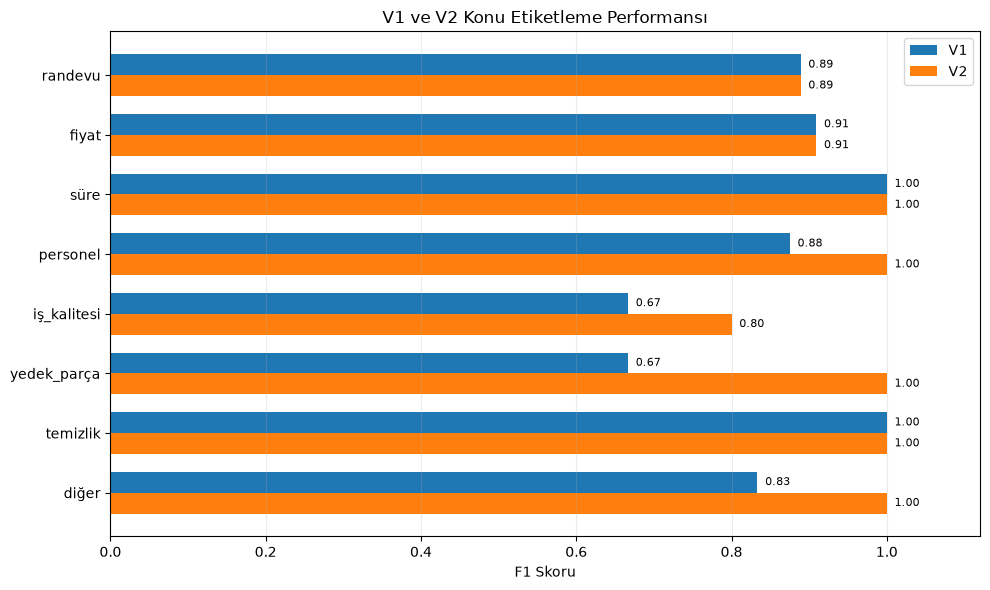

Grafik kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\llm_v1_v2_konu_f1_karsilastirmasi.png


In [42]:
import matplotlib.pyplot as plt
import numpy as np

grafik_verisi = konu_karsilastirma.copy()

konular = grafik_verisi["Konu"].tolist()
v1_skorlari = grafik_verisi["V1_F1"].tolist()
v2_skorlari = grafik_verisi["V2_F1"].tolist()

y = np.arange(len(konular))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(y - bar_width/2, v1_skorlari, bar_width, label="V1")
ax.barh(y + bar_width/2, v2_skorlari, bar_width, label="V2")

ax.set_yticks(y)
ax.set_yticklabels(konular)
ax.set_xlim(0, 1.12)
ax.set_xlabel("F1 Skoru")
ax.set_title("V1 ve V2 Konu Etiketleme Performansı")
ax.legend()
ax.grid(axis="x", alpha=0.25)

for i, (v1_s, v2_s) in enumerate(zip(v1_skorlari, v2_skorlari)):
    ax.text(v1_s + 0.01, i - bar_width/2, f"{v1_s:.2f}", va="center", fontsize=8)
    ax.text(v2_s + 0.01, i + bar_width/2, f"{v2_s:.2f}", va="center", fontsize=8)

ax.invert_yaxis()
plt.tight_layout()

grafik_yolu = ANALIZ_DIR / "llm_v1_v2_konu_f1_karsilastirmasi.png"
plt.savefig(grafik_yolu, dpi=300, bbox_inches="tight")
plt.show()

print("Grafik kaydedildi:", grafik_yolu)

In [43]:
from pathlib import Path

RAPOR_DOSYASI = ANALIZ_DIR / "06_llm_metin_analizi_raporu.md"

rapor = r"""
# 06 — LLM ile Müşteri Geri Bildirimlerinin Analizi

## 1. Amaç ve yöntem

Müşteri geri bildirimlerinin duygu ve konu bakımından sınıflandırılması,
LLM çıktılarının doğruluğunun ölçülmesi ve olumsuz geri bildirim
veren yüksek churn riskli müşteriler için aksiyon önerileri
oluşturulması amaçlanmıştır.

Analizde `geri_bildirimler_temiz.csv` kullanılmıştır. Toplam 640
geri bildirimin 11 tanesinde metin bulunmadığından 629 kullanılabilir
geri bildirim değerlendirmeye alınmıştır.

Bu kayıtlar arasından `random_state=42` kullanılarak rastgele
200 geri bildirim seçilmiştir. Etiketleme için Google Gemini API
üzerinden `gemini-3.5-flash-lite` modeli kullanılmıştır.

Modelden her geri bildirim için aşağıdaki alanlar istenmiştir:

- **Duygu:** Olumlu, Olumsuz, Karışık, Alakasız
- **Konular:** randevu, fiyat, süre, personel, iş_kalitesi,
  yedek_parça, temizlik, diğer

Çıktılar yapılandırılmış JSON formatında alınmış ve
`llm_etiketleri.csv` dosyasına kaydedilmiştir. API kaynaklı
429 ve 503 hataları nedeniyle bazı kayıtlar yeniden denenmiş,
sonuçta 200 kaydın tamamı başarıyla etiketlenmiştir.

## 2. Altın set ve V1 kalite ölçümü

Seçilen 200 geri bildirimin 40 tanesi rastgele belirlenerek
elle etiketlenmiştir. Bu kayıtlar altın set olarak kullanılmıştır.
Altın set ile V1 LLM çıktıları `geri_bildirim_id` üzerinden
eşleştirilmiş ve bire bir kayıt kontrolü yapılmıştır.

### 2.1. Duygu sınıflandırması

V1 duygu sınıflandırmasında 40 kaydın tamamı doğru etiketlenmiştir.

| Duygu | Destek |
|---|---:|
| Olumlu | 18 |
| Olumsuz | 13 |
| Karışık | 9 |
| Alakasız | 0 |
| **Toplam** | **40** |

| Metrik | Sonuç |
|---|---:|
| Doğru sınıflandırılan kayıt | 40 |
| Toplam kayıt | 40 |
| Accuracy | %100 |

**Sınırlılık:** Altın sette Alakasız sınıfına ait örnek bulunmadığından
bu sınıfın performansı ölçülememiştir. Dolayısıyla %100 doğruluk,
modelin tüm duygu sınıflarında aynı başarıyı göstereceği anlamına gelmez.

### 2.2. Çoklu konu sınıflandırması

V1 çoklu etiket değerlendirmesinde mikro F1, makro F1 ve tam
eşleşme oranı birlikte incelenmiştir.

| Metrik | V1 sonucu |
|---|---:|
| Micro Precision | 0,8983 |
| Micro Recall | 0,8154 |
| Micro F1 | 0,8548 |
| Macro F1 | 0,8584 |
| Exact Match | %70 (28/40) |

Konu bazında F1 sonuçları:

| Konu | Precision | Recall | F1 | Destek |
|---|---:|---:|---:|---:|
| randevu | 1,000 | 0,750 | 0,857 | 8 |
| fiyat | 0,857 | 0,857 | 0,857 | 7 |
| süre | 0,846 | 1,000 | 0,917 | 11 |
| personel | 1,000 | 0,692 | 0,818 | 13 |
| iş_kalitesi | 1,000 | 0,667 | 0,800 | 9 |
| yedek_parça | 0,667 | 1,000 | 0,800 | 2 |
| temizlik | 1,000 | 1,000 | 1,000 | 4 |
| diğer | 0,818 | 0,818 | 0,818 | 11 |

Tam eşleşme, bir geri bildirimin bütün konu etiketlerinin
eksiksiz doğru tahmin edilmesini gerektirir. Bu nedenle
mikro F1 değerinden daha düşük gerçekleşmiştir.

Küçük destek sayısına sahip sınıfların sonuçları temkinli
yorumlanmalıdır. Özellikle yedek_parça sınıfında altın sette
yalnızca iki örnek bulunmaktadır.

## 3. Sistematik hata analizi

V1 değerlendirmesinde 40 kaydın 12'sinde en az bir konu etiketi
uyuşmazlığı görülmüştür. İnceleme sonucunda aşağıdaki hata
örüntüleri belirlenmiştir.

### 3.1. Personel ve iletişim etiketinin eksik atanması

Model bazı iletişim, erişim ve bilgilendirme sorunlarında
`personel` etiketini atlamıştır.

**Örnek — Geri bildirim 9383:**

> Telefonla kimseye ulaşamıyorum, çağrı merkezi sürekli meşg.

- Manuel etiket: randevu; personel
- LLM etiketi: diğer

**Örnek — Geri bildirim 9621:**

> Fatura tutarı verilen tekliften yüksek çıktı, önceden bilgilendirilmedim.

- Manuel etiket: fiyat; personel
- LLM etiketi: fiyat

Bu örnekler, çağrı merkezi erişimi ve müşteriye bilgi verilmemesi
gibi durumlarda iletişim boyutunun eksik yakalanabildiğini
göstermektedir.

### 3.2. İş kalitesi etiketinin eksik atanması

Bazı geri bildirimlerde model temel sorunu tespit etmesine
rağmen iş kalitesiyle ilişkili ikinci etiketi atlamıştır.

**Örnek — Geri bildirim 9013:**

> Aracımın içinde yağ lekesi bıraktılar, koltuk kirlenmişti.

- Manuel etiket: temizlik; iş_kalitesi
- LLM etiketi: temizlik

Benzer hata 9295 numaralı, aynı metne sahip geri bildirimde
de görülmüştür.

### 3.3. Benzer kavramların karıştırılması

**Örnek — Geri bildirim 9084:**

> Yedek araç verilmesi büyük kolaylık oldu.

- Manuel etiket: diğer
- LLM etiketi: yedek_parça

Model, yedek araç ifadesini yedek parça kategorisiyle
ilişkilendirmiştir. Oysa iki kavram farklıdır.

### 3.4. Metinde açıkça belirtilmeyen konuların atanması

**Örnek — Geri bildirim 9370:**

> Arıza giderilmemiş, aynı ses devam ediyor. Tekrar gitmek zorunda kaldım.

- Manuel etiket: iş_kalitesi
- LLM etiketi: iş_kalitesi; süre

Model, tekrar servis ziyaretini süre problemi olarak
yorumlamıştır. Ancak metinde doğrudan bir bekleme,
gecikme veya işlem süresi sorunu belirtilmemiştir.
Aynı hata 9633 numaralı geri bildirimde de görülmüştür.

### 3.5. Diğer gözlemler

9343 numaralı geri bildirimde şubede geçerli olmayan kampanya
mesajı nedeniyle oluşan fiyat boyutu atlanmıştır. 9348 numaralı
geri bildirimde ise POS cihazı arızası fiyat etiketiyle
ilişkilendirilmiştir. Bu örnekler, konu kategorilerinin
sınırlarının daha açık tanımlanması gerektiğini göstermektedir.

### 3.6. Hata analizi sonucu ve sınırlılıklar

Hata analizi; personel/iletişim ve iş kalitesi gibi ikincil
etiketlerin atlanması, benzer kavramların karıştırılması ve
metinde açıkça belirtilmeyen konuların atanması eğilimlerini
ortaya koymuştur.

Bazı uyuşmazlıklar aynı metne sahip geri bildirimlerde
tekrarlanmıştır. Bu nedenle 12 uyuşmazlık birbirinden bağımsız
12 hata örüntüsü olarak değerlendirilmemelidir.

Altın set tek bir kişi tarafından etiketlenmiştir. İkinci bir
etiketleyiciyle bağımsız tutarlılık ölçümü yapılmadığından,
bazı konu etiketleri yorum farklılığı içerebilir.

## 4. Prompt iyileştirmesi ve V1–V2 karşılaştırması (Bonus)

V1 hata analizinde belirlenen sorunları azaltmak amacıyla
sınıflandırma promptu V2 olarak güncellenmiştir.

V2 promptunda özellikle:

- Personel etiketinin iletişim, müşteriyle temas ve
  bilgilendirme sorunlarını da kapsaması netleştirilmiştir.
- Yedek araç ile yedek parça kavramları birbirinden ayrılmıştır.
- Süre etiketinin yalnızca açık bekleme, gecikme veya
  işlem süresi ifadelerinde kullanılması belirtilmiştir.
- Birden fazla konu açıkça destekleniyorsa çoklu etiket
  atanması, `diğer` etiketinin ise yalnızca listelenen
  konuların hiçbiri uygun değilse kullanılması açıklanmıştır.

Karşılaştırmada model değiştirilmemiş, V1 ve V2 için aynı
`gemini-3.5-flash-lite` modeli kullanılmıştır. Böylece temel
değişiklik prompt içeriği olmuştur.

### 4.1. Karşılaştırma örneklemi

Ücretsiz API kullanım sınırları nedeniyle V2 aşamasında
40 altın set kaydının ilk aşamada yalnızca 25'i tamamlanabilmiştir.
Bu nedenle V1 ve V2 karşılaştırması, her iki sürümde de
sonucu bulunan aynı 25 kayıt üzerinden yapılmıştır.

Kalan 15 kayıt geçici olarak beklemeye alınmıştır.
Bu bölümdeki sonuçlar 40 kayıtlık nihai değerlendirme
olarak yorumlanmamalıdır.

### 4.2. Duygu sınıflandırması karşılaştırması

| Metrik | V1 | V2 |
|---|---:|---:|
| Doğru tahmin | 25/25 | 25/25 |
| Accuracy | %100 | %100 |

Ortak 25 kaydın tamamında her iki sürüm de olumlu, olumsuz
ve karışık duygu etiketlerini doğru tahmin etmiştir.
Prompt iyileştirmesi bu örneklemde duygu sınıflandırmasına
ek bir performans artışı sağlamamıştır.

Bu 25 kayıtta Alakasız sınıfı bulunmadığından bu sınıf
değerlendirilememiştir.

### 4.3. Çoklu konu sınıflandırması karşılaştırması

| Metrik | V1 | V2 | Değişim |
|---|---:|---:|---:|
| Micro Precision | 0,9459 | 1,0000 | +0,0541 |
| Micro Recall | 0,8140 | 0,9070 | +0,0930 |
| Micro F1 | 0,8750 | 0,9512 | +0,0762 |
| Macro Precision | 0,9167 | 1,0000 | +0,0833 |
| Macro Recall | 0,8431 | 0,9125 | +0,0694 |
| Macro F1 | 0,8550 | 0,9497 | +0,0947 |
| Exact Match | %72 | %84 | +12 puan |

Konu bazında F1 karşılaştırması:

| Konu | V1 F1 | V2 F1 | Değişim |
|---|---:|---:|---:|
| randevu | 0,8889 | 0,8889 | 0,0000 |
| fiyat | 0,9091 | 0,9091 | 0,0000 |
| süre | 1,0000 | 1,0000 | 0,0000 |
| personel | 0,8750 | 1,0000 | +0,1250 |
| iş_kalitesi | 0,6667 | 0,8000 | +0,1333 |
| yedek_parça | 0,6667 | 1,0000 | +0,3333 |
| temizlik | 1,0000 | 1,0000 | 0,0000 |
| diğer | 0,8333 | 1,0000 | +0,1667 |

V2, ortak 25 kayıtta konu etiketleme performansını artırmıştır.
Micro F1 0,8750'ten 0,9512'ye, Macro F1 0,8550'ten
0,9497'ye yükselmiştir. Exact Match oranı %72'den %84'e
çıkmıştır.

V2'nin Micro Precision değeri 1,00 olmuş; bu örneklemde
yanlış konu etiketi üretmemiştir. En belirgin F1 artışları
personel, iş_kalitesi, yedek_parça ve diğer kategorilerinde
görülmüştür.

Bununla birlikte yedek_parça kategorisinin desteği yalnızca
bir kayıt olduğundan bu kategorideki artış genellenmemelidir.
Sonuçlar 25 kayıtla sınırlıdır ve kalan 15 kayıt tamamlandığında
aynı değerlendirme 40 kayıt üzerinden tekrarlanacaktır.

## 5. Yüksek churn riski ve olumsuz geri bildirim analizi

Churn modelinin test setinde ürettiği müşteri bazlı olasılıklar
ile LLM tarafından incelenen olumsuz geri bildirimler
eşleştirilmiştir.

Churn olasılığı 0,55 ve üzerinde olan 160 test müşterisi
yüksek riskli aday olarak değerlendirilmiştir.

İncelenen 200 geri bildirimlik örneklemde olumsuz geri bildirimi
bulunan üç yüksek riskli müşteri belirlenmiştir.

| Müşteri ID | Churn olasılığı | Gerçek churn | Olumsuz geri bildirim |
|---|---:|---:|---|
| 102827 | %73,21 | 0 | Çağrı merkezine ulaşılamaması |
| 103816 | %70,20 | 1 | POS cihazı nedeniyle ödeme sorunu |
| 103687 | %69,30 | 0 | Danışmanın yetersiz bilgilendirmesi |

### 5.1. Aksiyon önerileri

**Müşteri 102827 — Çağrı merkezine erişim sorunu**

Müşteriye güncel iletişim numarası üzerinden ulaşılması,
yaşadığı erişim sorununun dinlenmesi ve gerekiyorsa
servis/randevu sürecinde destek sağlanması önerilmiştir.

**Müşteri 103816 — Ödeme sorunu**

POS cihazı arızasının nedeni ilgili teknik birimle araştırılmalı
ve benzer aksaklıkların tekrarlanmaması için gerekli kontrol
sağlanmalıdır.

**Müşteri 103687 — Danışman iletişimi**

Müşterinin yanıt alamadığı konu ilgili birimden netleştirilmeli
ve müşteri yeniden aranarak doğru ve yeterli bilgilendirme
yapılmalıdır.

Bu öneriler LLM tarafından oluşturulmuş, ardından insan
kontrolünden geçirilmiştir. Önerilerde doğrulanmamış indirim,
kampanya veya hizmet vaadi oluşturulmamıştır.

**Önemli sınırlılık:** Bu üç müşteri, yalnızca LLM tarafından
incelenen 200 geri bildirimlik örneklemde olumsuz geri bildirimi
bulunan test müşterileridir. Tüm müşteri kitlesinde olumsuz
geri bildirimi bulunan müşteri sayısını temsil etmezler.

Ayrıca 102827 ve 103687 numaralı müşterilerin gerçek churn
etiketi 0'dır. Bu durum, yüksek risk tahmininin her müşteri
için gerçekleşmediğini ve modelin yanlış pozitif üretebildiğini
göstermektedir.

## 6. Şirketin sunmadığı kampanya ve tekliflerin önlenmesi

LLM'in şirket tarafından sunulmayan indirim, kampanya, hediye,
ücretsiz hizmet veya tazminat gibi vaatlerde bulunmasını
önlemek için üç katmanlı kontrol önerilmektedir:

1. **Prompt kısıtları:** Modelden yalnızca verilen geri bildirim
   ve doğrulanmış bilgiler üzerinden öneri üretmesi istenir.
   Şirket tarafından doğrulanmamış kampanya veya avantaj
   vaat etmesi açıkça yasaklanır.
2. **Onaylı bilgi kaynağı:** Aksiyon önerileri yalnızca şirketin
   onaylı hizmet politikaları ve doğrulanmış uygulamalarıyla
   sınırlandırılır. Bilgi bulunmuyorsa ilgili birime danışılması
   önerilir.
3. **İnsan kontrolü:** LLM çıktısı doğrudan müşteriye gönderilmez.
   Müşteri temsilcisi veya yetkili çalışan tarafından kontrol
   edildikten sonra kullanılır.

Bu yaklaşım, LLM'in doğrulanmamış ticari vaatlerde bulunma
riskini azaltır.

## 7. Genel değerlendirme

Çalışmada LLM, müşteri geri bildirimlerini yapılandırılmış
duygu ve konu etiketlerine dönüştürmek için kullanılmıştır.
V1'in 40 kayıtlık altın set değerlendirmesinde duygu
sınıflandırma doğruluğu %100, konu sınıflandırma Micro F1
skoru 0,8548 ve Exact Match oranı %70 olarak ölçülmüştür.

V1 hata analizi sonucunda konu tanımlarının netleştirilmesi
ve çoklu etiket kurallarının geliştirilmesiyle V2 promptu
oluşturulmuştur. Ortak 25 kayıt üzerindeki ön karşılaştırmada
V2'nin konu sınıflandırma Micro F1 skoru 0,9512'ye,
Exact Match oranı %84'e yükselmiştir. Duygu sınıflandırmasında
ise her iki sürüm de %100 doğruluk elde etmiştir.

V2 karşılaştırması henüz 25 kayıtla sınırlıdır. Kalan 15 kayıt
tamamlandığında 40 kayıtlık değerlendirme güncellenecektir.

LLM çıktıları müşteri aksiyonları için yardımcı karar desteği
olarak değerlendirilmiş; nihai öneriler insan kontrolüne
tabi tutulmuştur.
"""

RAPOR_DOSYASI.write_text(rapor.strip(), encoding="utf-8")

print("Rapor oluşturuldu:", RAPOR_DOSYASI)
print("Dosya boyutu:", round(RAPOR_DOSYASI.stat().st_size / 1024, 2), "KB")
print("\nRaporun ilk 25 satırı:\n")
print("\n".join(rapor.splitlines()[:25]))

Rapor oluşturuldu: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\06_llm_metin_analizi_raporu.md
Dosya boyutu: 13.69 KB

Raporun ilk 25 satırı:


# 06 — LLM ile Müşteri Geri Bildirimlerinin Analizi

## 1. Amaç ve yöntem

Müşteri geri bildirimlerinin duygu ve konu bakımından sınıflandırılması,
LLM çıktılarının doğruluğunun ölçülmesi ve olumsuz geri bildirim
veren yüksek churn riskli müşteriler için aksiyon önerileri
oluşturulması amaçlanmıştır.

Analizde `geri_bildirimler_temiz.csv` kullanılmıştır. Toplam 640
geri bildirimin 11 tanesinde metin bulunmadığından 629 kullanılabilir
geri bildirim değerlendirmeye alınmıştır.

Bu kayıtlar arasından `random_state=42` kullanılarak rastgele
200 geri bildirim seçilmiştir. Etiketleme için Google Gemini API
üzerinden `gemini-3.5-flash-lite` modeli kullanılmıştır.

Modelden her geri bildirim için aşağıdaki alanlar istenmiştir:

- **Duygu:** Olumlu, Olumsuz, Karışık, Alakasız
- **Konular:** randevu, fiyat, süre, personel